# 04 — Closed-Loop Evaluation and Critical Analysis

## Robustness-Enhanced Vision-Language-Action Learning

**Module:** Deep Learning (`CT100-3-M-DL`)  
**Programme:** Master in Artificial Intelligence  
**Framework:** Hugging Face LeRobot `v0.6.1`  
**Benchmark:** LIBERO-Spatial  
**Primary comparison:** M1 standard fine-tuning vs M2-LE combined robustness fine-tuning

---

### Notebook objective

Notebooks 00–03 established the data, simulator, training pipeline, hyperparameter search and final checkpoints.

Notebook 04 answers the actual research question:

> **Does robustness-oriented fine-tuning improve closed-loop robotic manipulation under linguistic and visual distribution shifts?**

The notebook is intentionally evaluation-heavy because the Assignment 2 rubric requires final evaluation, visualization and critical analysis.

A clean `Run All` performs:

1. prerequisite and checkpoint audit,
2. training-budget adequacy diagnostic,
3. high-level architecture visualization,
4. frozen evaluation design and compute-budget audit,
5. closed-loop timing calibration,
6. single-seed ablation evaluation,
7. three-seed M1 vs M2-LE confirmatory evaluation,
8. per-seed bootstrap uncertainty,
9. across-seed mean ± standard deviation,
10. paired success comparisons,
11. generalization-gap analysis,
12. per-task and per-condition visualizations,
13. failure-proxy analysis and manual review template,
14. research-question evidence table,
15. final reproducibility summary.

### Scope boundary

This notebook makes **no unsupported claim** that the evaluation reproduces every LIBERO-Plus perturbation category.

The core controlled shifts evaluated here are:

- linguistic variation (L1, L2, held-out L3),
- a **seen photometric shift** at the boundary of the M2-E training augmentation,
- a **held-out Gaussian sensor-noise category** not used during training,
- a combined held-out-language + seen-photometric condition.

Camera-pose, object-layout and robot-initial-state perturbation suites are left as explicit future extensions unless separately implemented and validated.

## 1. Experimental hypotheses and research questions

### Research questions

- **RQ1:** Does robustness-oriented fine-tuning improve success under seen perturbation types?
- **RQ2:** How does SmolVLA performance degrade as language wording moves from L0 to L3?
- **RQ3:** Which tested visual perturbation produces the strongest degradation?
- **RQ4:** Does robustness training transfer to a held-out perturbation category?
- **RQ5:** Is improved robustness associated with an in-distribution performance trade-off?

### Interpretation rule

Offline validation loss from Notebook 03 is **not** the primary outcome.

The primary outcome in this notebook is **closed-loop task success rate (SR)**.

For any OOD condition `c`:

\[
G_c = SR_{ID} - SR_c
\]

where a smaller positive generalization gap indicates less degradation from ID performance.

## 2. Environment, paths and prerequisite audit

In [2]:
import os

# Graphics variables must be defined before MuJoCo / LIBERO imports.
os.environ.setdefault("GALLIUM_DRIVER", "d3d12")
os.environ.setdefault("MESA_D3D12_DEFAULT_ADAPTER_NAME", "NVIDIA")
os.environ.setdefault("MUJOCO_GL", "glfw")

from pathlib import Path
from datetime import datetime
import gc
import hashlib
import json
import math
import random
import shutil
import subprocess
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
LIBERO_SUITE = "libero_spatial"

# Frozen evaluation replication.
EPISODES_PER_TASK = 3
BOOTSTRAP_SAMPLES = 2000
BOOTSTRAP_SEED = 2026

PRIMARY_VARIANTS = {"M1", "M2-LE"}
PRIMARY_SEEDS = [42, 123, 2026]

def find_repo_root(start: Path) -> Path:
    current = start.resolve()
    for candidate in [current, *current.parents]:
        if (candidate / ".git").exists():
            return candidate
    if current.name == "notebooks":
        return current.parent
    return current

REPO_ROOT = find_repo_root(Path.cwd())

CONFIG_DIR = REPO_ROOT / "configs"
EXPERIMENT_CONFIG_DIR = CONFIG_DIR / "experiments"

RESULTS_DIR = REPO_ROOT / "results"
METRICS_DIR = RESULTS_DIR / "metrics" / "evaluation_critical_analysis"
FIGURES_DIR = RESULTS_DIR / "figures" / "evaluation_critical_analysis"
QUALITATIVE_DIR = FIGURES_DIR / "qualitative_task0"

for directory in [
    EXPERIMENT_CONFIG_DIR,
    METRICS_DIR,
    FIGURES_DIR,
    QUALITATIVE_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

NOTEBOOK03_SUMMARY_PATH = (
    REPO_ROOT
    / "results"
    / "metrics"
    / "tuning_final_training"
    / "notebook03_summary.json"
)

assert NOTEBOOK03_SUMMARY_PATH.exists(), (
    f"Notebook 03 summary not found: {NOTEBOOK03_SUMMARY_PATH}"
)

with open(NOTEBOOK03_SUMMARY_PATH, "r") as f:
    notebook03_summary = json.load(f)

assert notebook03_summary["status"] == "PASS", (
    "Notebook 04 requires Notebook 03 STATUS = PASS."
)

evaluation_handoff_path = (
    REPO_ROOT
    / notebook03_summary["evaluation_handoff"]
)

assert evaluation_handoff_path.exists()

with open(evaluation_handoff_path, "r") as f:
    evaluation_handoff = json.load(f)

assert evaluation_handoff["primary_metric"] == "task success rate"

def git_sha(repo_root: Path):
    try:
        return subprocess.check_output(
            ["git", "rev-parse", "HEAD"],
            cwd=repo_root,
            text=True,
        ).strip()
    except Exception:
        return None

PROJECT_GIT_SHA = git_sha(REPO_ROOT)

environment_summary = {
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "device": DEVICE,
    "gpu": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    ),
    "Notebook 03 status": notebook03_summary["status"],
    "final checkpoint count": len(evaluation_handoff["models"]),
    "episodes_per_task": EPISODES_PER_TASK,
    "project_git_sha": PROJECT_GIT_SHA,
}

display(pd.DataFrame([environment_summary]).T.rename(columns={0: "Value"}))

assert torch.cuda.is_available(), (
    "Closed-loop evaluation is configured for the validated CUDA environment."
)

print("NOTEBOOK 03 PREREQUISITE: PASS")

,Value
python,3.12.14
torch,2.11.0+cu128
device,cuda
gpu,NVIDIA GeForce RTX 5090
Notebook 03 status,PASS
final checkpoint count,8
episodes_per_task,3
project_git_sha,bf3d723e97e3e95b5b0d391efe9e13184f620a05


NOTEBOOK 03 PREREQUISITE: PASS


## 3. Final checkpoint and experiment-handoff audit

In [3]:
model_rows = []

for run_id, entry in evaluation_handoff["models"].items():
    checkpoint = REPO_ROOT / entry["checkpoint"]

    model_rows.append({
        "run_id": run_id,
        "variant": entry["variant"],
        "seed": int(entry["seed"]),
        "validation_loss": float(entry["validation_loss"]),
        "checkpoint": str(checkpoint.relative_to(REPO_ROOT)),
        "config_exists": (checkpoint / "config.json").exists(),
        "checkpoint_exists": checkpoint.exists(),
    })

model_registry_df = (
    pd.DataFrame(model_rows)
    .sort_values(["variant", "seed"])
    .reset_index(drop=True)
)

display(model_registry_df)

assert len(model_registry_df) == 8
assert model_registry_df["checkpoint_exists"].all()
assert model_registry_df["config_exists"].all()

assert len(
    model_registry_df[
        model_registry_df["variant"] == "M1"
    ]
) == 3

assert len(
    model_registry_df[
        model_registry_df["variant"] == "M2-LE"
    ]
) == 3

print("FINAL CHECKPOINT REGISTRY: PASS")

,run_id,variant,seed,validation_loss,checkpoint,config_exists,checkpoint_exists
0,M1_seed42,M1,42,0.647234,experiments/training/final/M1_seed42/model,True,True
1,M1_seed123,M1,123,0.663268,experiments/training/final/M1_seed123/model,True,True
2,M1_seed2026,M1,2026,0.662571,experiments/training/final/M1_seed2026/model,True,True
3,M2E_seed42,M2-E,42,0.642406,experiments/training/final/M2E_seed42/model,True,True
4,M2L_seed42,M2-L,42,0.657187,experiments/training/final/M2L_seed42/model,True,True
5,M2LE_seed42,M2-LE,42,0.653671,experiments/training/final/M2LE_seed42/model,True,True
6,M2LE_seed123,M2-LE,123,0.700583,experiments/training/final/M2LE_seed123/model,True,True
7,M2LE_seed2026,M2-LE,2026,0.644916,experiments/training/final/M2LE_seed2026/model,True,True


FINAL CHECKPOINT REGISTRY: PASS


## 4. Training-budget adequacy diagnostic

Notebook 03 froze a 1,500-step final training budget. Because training duration by itself is not evidence of adequacy, this section audits the **observed loss trajectory** for M1 and M2-LE seed 42.

This diagnostic does **not** claim mathematical convergence. It asks a narrower question:

> Did the final 1,500-step runs remain numerically stable and show evidence of substantially improved loss relative to their earlier logged training region?

If the late-window losses are still changing sharply, that is retained as a study limitation rather than hidden.

,run_id,step,loss,grad_norm,lr
110,M2LE_seed42,1225,0.835313,4.900945,0.000012
111,M2LE_seed42,1250,0.817414,6.848871,0.000011
112,M2LE_seed42,1275,0.614364,2.664270,0.000009
113,M2LE_seed42,1300,0.673050,4.357737,0.000008
114,M2LE_seed42,1325,0.599128,4.605132,0.000006
115,M2LE_seed42,1350,0.743578,5.071755,0.000005
116,M2LE_seed42,1375,0.488660,3.343448,0.000005
117,M2LE_seed42,1400,0.510629,3.770580,0.000004
118,M2LE_seed42,1425,0.565459,3.151932,0.000003
119,M2LE_seed42,1450,0.414663,3.617272,0.000003


,run_id,logged_points,early_window_mean_loss,late_window_mean_loss,relative_loss_reduction,finite_training_trace,interpretation
0,M1_seed42,61,1.456472,0.637438,0.562341,True,stable with lower late-window loss
1,M2LE_seed42,61,1.327712,0.609622,0.540848,True,stable with lower late-window loss


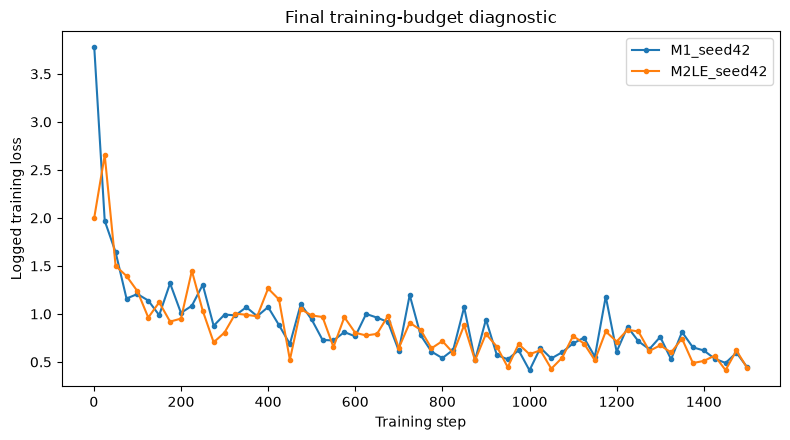

TRAINING-BUDGET NUMERICAL STABILITY: PASS
Note: this is an adequacy diagnostic, not a claim of full convergence.


In [4]:
FINAL_TRAINING_ROOT = (
    REPO_ROOT
    / "experiments"
    / "training"
    / "final"
)

budget_run_ids = [
    "M1_seed42",
    "M2LE_seed42",
]

budget_frames = []

for run_id in budget_run_ids:
    metrics_path = (
        FINAL_TRAINING_ROOT
        / run_id
        / "train_metrics.csv"
    )

    assert metrics_path.exists(), (
        f"Missing training metrics: {metrics_path}"
    )

    frame = pd.read_csv(metrics_path)
    frame["run_id"] = run_id
    budget_frames.append(frame)

budget_metrics_df = pd.concat(
    budget_frames,
    ignore_index=True,
)

display(
    budget_metrics_df[
        ["run_id", "step", "loss", "grad_norm", "lr"]
    ].tail(12)
)

budget_diagnostic_rows = []

for run_id, group in budget_metrics_df.groupby("run_id"):
    group = group.sort_values("step").reset_index(drop=True)

    n = len(group)
    window = max(3, n // 5)

    early_mean = float(
        group.head(window)["loss"].mean()
    )

    late_mean = float(
        group.tail(window)["loss"].mean()
    )

    relative_reduction = (
        (early_mean - late_mean)
        / max(abs(early_mean), 1e-12)
    )

    finite = bool(
        np.isfinite(group["loss"]).all()
        and np.isfinite(group["grad_norm"]).all()
    )

    budget_diagnostic_rows.append({
        "run_id": run_id,
        "logged_points": n,
        "early_window_mean_loss": early_mean,
        "late_window_mean_loss": late_mean,
        "relative_loss_reduction": relative_reduction,
        "finite_training_trace": finite,
        "interpretation": (
            "stable with lower late-window loss"
            if finite and late_mean < early_mean
            else "requires caution"
        ),
    })

budget_diagnostic_df = pd.DataFrame(
    budget_diagnostic_rows
)

display(budget_diagnostic_df)

budget_diagnostic_df.to_csv(
    METRICS_DIR / "training_budget_diagnostic.csv",
    index=False,
)

fig, ax = plt.subplots(figsize=(8, 4.5))

for run_id, group in budget_metrics_df.groupby("run_id"):
    ax.plot(
        group["step"],
        group["loss"],
        marker="o",
        markersize=3,
        label=run_id,
    )

ax.set_xlabel("Training step")
ax.set_ylabel("Logged training loss")
ax.set_title("Final training-budget diagnostic")
ax.legend()
fig.tight_layout()

budget_figure_path = (
    FIGURES_DIR
    / "training_budget_diagnostic.png"
)

fig.savefig(
    budget_figure_path,
    dpi=160,
    bbox_inches="tight",
)

plt.show()

TRAINING_TRACE_PASS = bool(
    budget_diagnostic_df["finite_training_trace"].all()
)

assert TRAINING_TRACE_PASS

print("TRAINING-BUDGET NUMERICAL STABILITY: PASS")
print(
    "Note: this is an adequacy diagnostic, not a claim of full convergence."
)

## 5. High-level architecture visualization

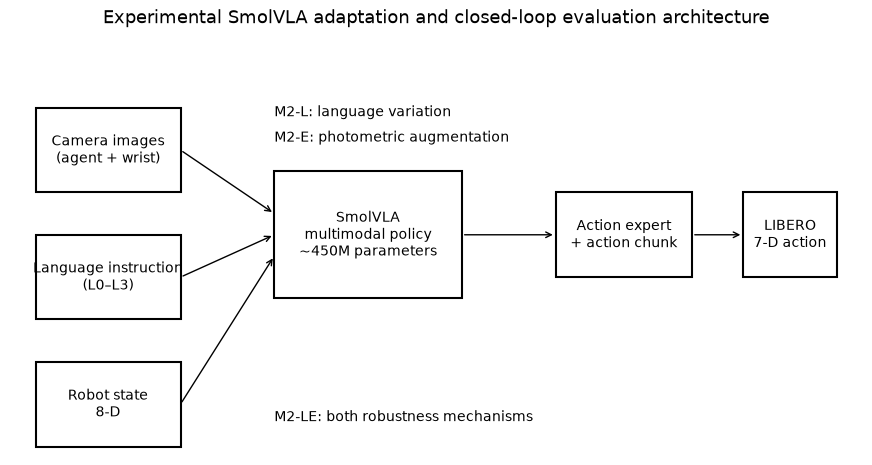

ARCHITECTURE VISUALIZATION: PASS


In [5]:
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.axis("off")

boxes = [
    (0.03, 0.62, 0.17, 0.20, "Camera images\n(agent + wrist)"),
    (0.03, 0.32, 0.17, 0.20, "Language instruction\n(L0–L3)"),
    (0.03, 0.02, 0.17, 0.20, "Robot state\n8-D"),
    (0.31, 0.37, 0.22, 0.30, "SmolVLA\nmultimodal policy\n~450M parameters"),
    (0.64, 0.42, 0.16, 0.20, "Action expert\n+ action chunk"),
    (0.86, 0.42, 0.11, 0.20, "LIBERO\n7-D action"),
]

for x, y, w, h, label in boxes:
    rect = plt.Rectangle(
        (x, y),
        w,
        h,
        fill=False,
        linewidth=1.5,
    )
    ax.add_patch(rect)
    ax.text(
        x + w / 2,
        y + h / 2,
        label,
        ha="center",
        va="center",
        fontsize=10,
    )

arrow_pairs = [
    ((0.20, 0.72), (0.31, 0.57)),
    ((0.20, 0.42), (0.31, 0.52)),
    ((0.20, 0.12), (0.31, 0.47)),
    ((0.53, 0.52), (0.64, 0.52)),
    ((0.80, 0.52), (0.86, 0.52)),
]

for start, end in arrow_pairs:
    ax.annotate(
        "",
        xy=end,
        xytext=start,
        arrowprops=dict(arrowstyle="->"),
    )

ax.text(
    0.31,
    0.80,
    "M2-L: language variation",
    fontsize=10,
)

ax.text(
    0.31,
    0.74,
    "M2-E: photometric augmentation",
    fontsize=10,
)

ax.text(
    0.31,
    0.08,
    "M2-LE: both robustness mechanisms",
    fontsize=10,
)

ax.set_title(
    "Experimental SmolVLA adaptation and closed-loop evaluation architecture",
    fontsize=13,
)

architecture_figure_path = (
    FIGURES_DIR / "smolvla_experiment_architecture.png"
)

fig.savefig(
    architecture_figure_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

print("ARCHITECTURE VISUALIZATION: PASS")

## 6. Load task mapping and frozen language perturbations

LIBERO environment task IDs are `0–9`, whereas the LeRobot dataset uses task indices `30–39` for LIBERO-Spatial.

The mapping frozen in Notebook 00 is therefore loaded explicitly instead of assuming that both ID systems are identical.

In [6]:
TASK_MAPPING_PATH = (
    REPO_ROOT
    / "results"
    / "metrics"
    / "dataset_eda"
    / "libero_spatial_dataset_task_mapping.csv"
)

LANGUAGE_TABLE_PATH = (
    REPO_ROOT
    / "configs"
    / "experiments"
    / "libero_spatial_language_augmentations_v1.csv"
)

assert TASK_MAPPING_PATH.exists()
assert LANGUAGE_TABLE_PATH.exists()

task_mapping_df = pd.read_csv(TASK_MAPPING_PATH)
language_df = pd.read_csv(LANGUAGE_TABLE_PATH)

required_mapping_columns = {
    "suite_task_id",
    "dataset_task_index",
    "benchmark_instruction",
}

assert required_mapping_columns.issubset(
    task_mapping_df.columns
)

assert len(task_mapping_df) == 10
assert task_mapping_df["suite_task_id"].nunique() == 10
assert task_mapping_df["dataset_task_index"].nunique() == 10

suite_to_dataset_task = {
    int(row["suite_task_id"]): int(row["dataset_task_index"])
    for _, row in task_mapping_df.iterrows()
}

language_lookup = {
    (int(row["task_id"]), str(row["level"])): str(row["augmented_instruction"])
    for _, row in language_df.iterrows()
}

for suite_task_id, dataset_task_id in suite_to_dataset_task.items():
    for level in ["L0", "L1", "L2", "L3"]:
        assert (dataset_task_id, level) in language_lookup

display(
    task_mapping_df[
        [
            "suite_task_id",
            "dataset_task_index",
            "benchmark_instruction",
        ]
    ]
)

print("TASK + LANGUAGE MAPPING: PASS")

,suite_task_id,dataset_task_index,benchmark_instruction
0,0,34,pick up the black bowl between the plate and t...
1,1,37,pick up the black bowl next to the ramekin and...
2,2,38,pick up the black bowl from table center and p...
3,3,35,pick up the black bowl on the cookie box and p...
4,4,31,pick up the black bowl in the top drawer of th...
5,5,32,pick up the black bowl on the ramekin and plac...
6,6,30,pick up the black bowl next to the cookie box ...
7,7,33,pick up the black bowl on the stove and place ...
8,8,36,pick up the black bowl next to the plate and p...
9,9,39,pick up the black bowl on the wooden cabinet a...


TASK + LANGUAGE MAPPING: PASS


## 7. Frozen evaluation conditions

### Conditions

| ID | Language | Visual condition | Training relation |
|---|---|---|---|
| E0_ID | L0 | none | ID reference |
| E1_L1 | L1 | none | seen language category |
| E1_L2 | L2 | none | seen language category |
| E1_L3 | L3 | none | **held-out language category** |
| E2_SEEN_PHOTO | L0 | fixed photometric boundary shift | seen visual augmentation family |
| E3_HELDOUT_NOISE | L0 | Gaussian sensor noise | **held-out visual category** |
| E4_COMBINED | L3 | fixed photometric boundary shift | held-out language + seen visual family |

The fixed E2 photometric stress uses values at the edge of the training augmentation range.  
E3 Gaussian noise was not used during training and therefore tests category transfer.

In [7]:
CONDITIONS = {
    "E0_ID": {
        "label": "ID / L0",
        "language_level": "L0",
        "image_shift": "NONE",
        "shift_role": "ID",
    },
    "E1_L1": {
        "label": "Language L1",
        "language_level": "L1",
        "image_shift": "NONE",
        "shift_role": "seen_language",
    },
    "E1_L2": {
        "label": "Language L2",
        "language_level": "L2",
        "image_shift": "NONE",
        "shift_role": "seen_language",
    },
    "E1_L3": {
        "label": "Language L3 held-out",
        "language_level": "L3",
        "image_shift": "NONE",
        "shift_role": "heldout_language",
    },
    "E2_SEEN_PHOTO": {
        "label": "Seen photometric shift",
        "language_level": "L0",
        "image_shift": "SEEN_PHOTO",
        "shift_role": "seen_visual",
    },
    "E3_HELDOUT_NOISE": {
        "label": "Held-out sensor noise",
        "language_level": "L0",
        "image_shift": "HELDOUT_NOISE",
        "shift_role": "heldout_visual",
    },
    "E4_COMBINED": {
        "label": "L3 + photometric",
        "language_level": "L3",
        "image_shift": "SEEN_PHOTO",
        "shift_role": "combined",
    },
}

condition_df = pd.DataFrame(
    [
        {
            "condition_id": condition_id,
            **condition,
        }
        for condition_id, condition in CONDITIONS.items()
    ]
)

display(condition_df)

condition_manifest_path = (
    EXPERIMENT_CONFIG_DIR
    / "evaluation_conditions_v1.json"
)

with open(condition_manifest_path, "w") as f:
    json.dump(CONDITIONS, f, indent=2)

print("EVALUATION CONDITIONS: FROZEN")

,condition_id,label,language_level,image_shift,shift_role
0,E0_ID,ID / L0,L0,NONE,ID
1,E1_L1,Language L1,L1,NONE,seen_language
2,E1_L2,Language L2,L2,NONE,seen_language
3,E1_L3,Language L3 held-out,L3,NONE,heldout_language
4,E2_SEEN_PHOTO,Seen photometric shift,L0,SEEN_PHOTO,seen_visual
5,E3_HELDOUT_NOISE,Held-out sensor noise,L0,HELDOUT_NOISE,heldout_visual
6,E4_COMBINED,L3 + photometric,L3,SEEN_PHOTO,combined


EVALUATION CONDITIONS: FROZEN


## 8. Evaluation matrix and compute-budget closure

The evaluation is intentionally staged.

### Phase A — component ablations, seed 42

- M1: all conditions
- M2-L: ID + L1/L2/L3
- M2-E: ID + seen photometric + held-out noise
- M2-LE: all conditions

### Phase B — primary three-seed confirmation

For M1 and M2-LE, seeds 42/123/2026 are compared on:

- E0 ID,
- held-out L3,
- seen photometric,
- held-out noise,
- combined L3 + photometric.

This avoids an unbounded all-model × all-seed × all-condition grid while preserving the main multi-seed comparison and clean ablations.

In [8]:
run_lookup = {
    (str(row["variant"]), int(row["seed"])): str(row["run_id"])
    for _, row in model_registry_df.iterrows()
}

phase_a_conditions = {
    "M1": [
        "E0_ID",
        "E1_L1",
        "E1_L2",
        "E1_L3",
        "E2_SEEN_PHOTO",
        "E3_HELDOUT_NOISE",
        "E4_COMBINED",
    ],
    "M2-L": [
        "E0_ID",
        "E1_L1",
        "E1_L2",
        "E1_L3",
    ],
    "M2-E": [
        "E0_ID",
        "E2_SEEN_PHOTO",
        "E3_HELDOUT_NOISE",
    ],
    "M2-LE": [
        "E0_ID",
        "E1_L1",
        "E1_L2",
        "E1_L3",
        "E2_SEEN_PHOTO",
        "E3_HELDOUT_NOISE",
        "E4_COMBINED",
    ],
}

primary_conditions = [
    "E0_ID",
    "E1_L3",
    "E2_SEEN_PHOTO",
    "E3_HELDOUT_NOISE",
    "E4_COMBINED",
]

plan_rows = []

# Phase A seed-42 ablations.
for variant, condition_ids in phase_a_conditions.items():
    run_id = run_lookup[(variant, 42)]

    for condition_id in condition_ids:
        plan_rows.append({
            "phase": "A_ablation_seed42",
            "run_id": run_id,
            "variant": variant,
            "model_seed": 42,
            "condition_id": condition_id,
        })

# Phase B adds only seeds 123 and 2026 because seed 42 cells above are reused.
for variant in ["M1", "M2-LE"]:
    for model_seed in [123, 2026]:
        run_id = run_lookup[(variant, model_seed)]

        for condition_id in primary_conditions:
            plan_rows.append({
                "phase": "B_primary_multiseed",
                "run_id": run_id,
                "variant": variant,
                "model_seed": model_seed,
                "condition_id": condition_id,
            })

evaluation_plan_df = (
    pd.DataFrame(plan_rows)
    .drop_duplicates(
        subset=["run_id", "condition_id"]
    )
    .sort_values(
        ["phase", "variant", "model_seed", "condition_id"]
    )
    .reset_index(drop=True)
)

evaluation_plan_df["task_count"] = 10
evaluation_plan_df["episodes_per_task"] = EPISODES_PER_TASK
evaluation_plan_df["episodes"] = (
    evaluation_plan_df["task_count"]
    * evaluation_plan_df["episodes_per_task"]
)

PLANNED_EPISODES = int(
    evaluation_plan_df["episodes"].sum()
)

display(evaluation_plan_df)

print("Unique model-condition cells:", len(evaluation_plan_df))
print("Episodes per cell           :", 10 * EPISODES_PER_TASK)
print("Total planned episodes      :", PLANNED_EPISODES)

evaluation_plan_path = (
    EXPERIMENT_CONFIG_DIR
    / "closed_loop_evaluation_plan_v1.csv"
)

evaluation_plan_df.to_csv(
    evaluation_plan_path,
    index=False,
)

assert PLANNED_EPISODES == 1230

print("EVALUATION COMPUTE BUDGET: CLOSED")

,phase,run_id,variant,model_seed,condition_id,task_count,episodes_per_task,episodes
0,A_ablation_seed42,M1_seed42,M1,42,E0_ID,10,3,30
1,A_ablation_seed42,M1_seed42,M1,42,E1_L1,10,3,30
2,A_ablation_seed42,M1_seed42,M1,42,E1_L2,10,3,30
3,A_ablation_seed42,M1_seed42,M1,42,E1_L3,10,3,30
4,A_ablation_seed42,M1_seed42,M1,42,E2_SEEN_PHOTO,10,3,30
5,A_ablation_seed42,M1_seed42,M1,42,E3_HELDOUT_NOISE,10,3,30
6,A_ablation_seed42,M1_seed42,M1,42,E4_COMBINED,10,3,30
7,A_ablation_seed42,M2E_seed42,M2-E,42,E0_ID,10,3,30
8,A_ablation_seed42,M2E_seed42,M2-E,42,E2_SEEN_PHOTO,10,3,30
9,A_ablation_seed42,M2E_seed42,M2-E,42,E3_HELDOUT_NOISE,10,3,30


Unique model-condition cells: 41
Episodes per cell           : 30
Total planned episodes      : 1230
EVALUATION COMPUTE BUDGET: CLOSED


## 9. Official LeRobot/LIBERO evaluation components

In [9]:
from lerobot.envs.configs import LiberoEnv as LiberoEnvConfig

try:
    from lerobot.envs.factory import (
        make_env,
        make_env_pre_post_processors,
    )
except ImportError:
    from lerobot.envs import (
        make_env,
        make_env_pre_post_processors,
    )

from lerobot.envs.utils import preprocess_observation
from lerobot.policies.factory import make_pre_post_processors
from lerobot.policies.smolvla.modeling_smolvla import SmolVLAPolicy
from lerobot.utils.constants import ACTION

print("LEROBOT EVALUATION COMPONENTS: READY")

/home/leeming/miniforge3/envs/vla-libero/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


LEROBOT EVALUATION COMPONENTS: READY


## 10. Deterministic observation perturbation functions

In [10]:
def apply_seen_photometric_shift(image: torch.Tensor):
    # Training family used brightness/contrast/saturation in [0.85, 1.15].
    # Evaluation uses a fixed boundary combination.
    x = image.to(torch.float32)

    # Brightness
    x = x * 0.85

    # Contrast
    mean = x.mean(
        dim=(-2, -1),
        keepdim=True,
    )
    x = (x - mean) * 1.15 + mean

    # Saturation for RGB tensors.
    if x.shape[-3] >= 3:
        rgb = x[..., :3, :, :]

        gray = (
            0.2989 * rgb[..., 0:1, :, :]
            + 0.5870 * rgb[..., 1:2, :, :]
            + 0.1140 * rgb[..., 2:3, :, :]
        )

        rgb = (
            gray
            + (rgb - gray) * 0.85
        )

        x = x.clone()
        x[..., :3, :, :] = rgb

    return x.clamp(0.0, 1.0)


def apply_heldout_sensor_noise(
    image: torch.Tensor,
    seed: int,
):
    x = image.to(torch.float32)

    generator = torch.Generator(
        device=x.device
    )
    generator.manual_seed(
        int(seed)
    )

    noise = torch.randn(
        x.shape,
        generator=generator,
        device=x.device,
        dtype=x.dtype,
    ) * 0.05

    return (x + noise).clamp(
        0.0,
        1.0,
    )


def perturb_observation_images(
    observation: dict,
    image_shift: str,
    episode_seed: int,
    step_index: int,
):
    output = dict(observation)

    camera_keys = sorted(
        [
            key
            for key in output
            if key.startswith(
                "observation.images."
            )
        ]
    )

    for camera_index, camera_key in enumerate(camera_keys):
        image = output[camera_key]

        if not isinstance(image, torch.Tensor):
            continue

        if image_shift == "NONE":
            shifted = image

        elif image_shift == "SEEN_PHOTO":
            shifted = (
                apply_seen_photometric_shift(
                    image
                )
            )

        elif image_shift == "HELDOUT_NOISE":
            deterministic_noise_seed = (
                int(episode_seed) * 10000
                + int(step_index) * 100
                + camera_index
            )

            shifted = (
                apply_heldout_sensor_noise(
                    image,
                    seed=deterministic_noise_seed,
                )
            )

        else:
            raise ValueError(
                f"Unknown image_shift: {image_shift}"
            )

        output[camera_key] = shifted

    return output


# Sanity test.
test_tensor = torch.full(
    (1, 3, 32, 32),
    0.5,
)

assert torch.isfinite(
    apply_seen_photometric_shift(
        test_tensor
    )
).all()

assert torch.isfinite(
    apply_heldout_sensor_noise(
        test_tensor,
        seed=42,
    )
).all()

print("OBSERVATION PERTURBATIONS: PASS")

OBSERVATION PERTURBATIONS: PASS


## 11. Closed-loop evaluation utilities

In [11]:
EPISODE_RESULTS_PATH = (
    METRICS_DIR
    / "closed_loop_episode_results.csv"
)

ERROR_LOG_PATH = (
    METRICS_DIR
    / "closed_loop_errors.jsonl"
)


def extract_success(info, reward_value):
    success = bool(
        reward_value > 0
    )

    if isinstance(info, dict):
        for key in (
            "is_success",
            "success",
        ):
            if key in info:
                try:
                    success = (
                        success
                        or bool(
                            np.asarray(
                                info[key]
                            ).reshape(-1)[0]
                        )
                    )
                except Exception:
                    pass

    return success


def get_condition_instruction(
    suite_task_id: int,
    language_level: str,
    original_instruction: str,
):
    if language_level == "L0":
        return original_instruction

    dataset_task_id = (
        suite_to_dataset_task[
            int(suite_task_id)
        ]
    )

    return language_lookup[
        (
            int(dataset_task_id),
            str(language_level),
        )
    ]


def build_env_config(
    suite_task_id: int,
):
    return LiberoEnvConfig(
        task=LIBERO_SUITE,
        task_ids=[int(suite_task_id)],
        obs_type="pixels_agent_pos",
        camera_name=(
            "agentview_image,"
            "robot0_eye_in_hand_image"
        ),
        init_states=True,
        observation_height=256,
        observation_width=256,
        control_mode="relative",
    )


def load_policy_bundle(
    checkpoint: Path,
    suite_task_id: int,
):
    torch.cuda.empty_cache()

    policy = (
        SmolVLAPolicy
        .from_pretrained(
            str(checkpoint),
            local_files_only=True,
        )
        .to(DEVICE)
    )

    policy.eval()

    preprocessor, postprocessor = (
        make_pre_post_processors(
            policy_cfg=policy.config,
            pretrained_path=str(checkpoint),
            preprocessor_overrides={
                "device_processor": {
                    "device": DEVICE,
                }
            },
        )
    )

    env_cfg = build_env_config(
        suite_task_id
    )

    env_preprocessor, env_postprocessor = (
        make_env_pre_post_processors(
            env_cfg=env_cfg,
            policy_cfg=policy.config,
        )
    )

    return (
        policy,
        preprocessor,
        postprocessor,
        env_cfg,
        env_preprocessor,
        env_postprocessor,
    )


def episode_key(
    run_id,
    condition_id,
    suite_task_id,
    replica,
):
    return (
        str(run_id),
        str(condition_id),
        int(suite_task_id),
        int(replica),
    )


def read_episode_cache():
    if not EPISODE_RESULTS_PATH.exists():
        return pd.DataFrame()

    return pd.read_csv(
        EPISODE_RESULTS_PATH
    )


def completed_episode_keys():
    cache = read_episode_cache()

    if cache.empty:
        return set()

    passed = cache[
        cache["system_status"] == "PASS"
    ]

    return {
        episode_key(
            row.run_id,
            row.condition_id,
            row.suite_task_id,
            row.replica,
        )
        for row in passed.itertuples()
    }


def append_episode_result(row):
    row_df = pd.DataFrame([row])

    if EPISODE_RESULTS_PATH.exists():
        existing = pd.read_csv(
            EPISODE_RESULTS_PATH
        )

        combined = pd.concat(
            [existing, row_df],
            ignore_index=True,
        )

        combined = combined.drop_duplicates(
            subset=[
                "run_id",
                "condition_id",
                "suite_task_id",
                "replica",
            ],
            keep="last",
        )

    else:
        combined = row_df

    combined.to_csv(
        EPISODE_RESULTS_PATH,
        index=False,
    )


def save_tensor_image(
    image_tensor,
    path: Path,
):
    x = image_tensor.detach().cpu()

    if x.ndim == 4:
        x = x[0]

    if (
        x.ndim == 3
        and x.shape[0] in (1, 3, 4)
    ):
        x = x.permute(
            1,
            2,
            0,
        )

    array = x.numpy()

    if array.shape[-1] == 1:
        array = array[..., 0]

    path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    plt.imsave(
        path,
        np.clip(
            array,
            0.0,
            1.0,
        ),
    )


print("CLOSED-LOOP EVALUATION UTILITIES: READY")

CLOSED-LOOP EVALUATION UTILITIES: READY


### One-episode rollout

In [12]:
def evaluate_one_episode(
    *,
    env,
    policy,
    preprocessor,
    postprocessor,
    env_preprocessor,
    env_postprocessor,
    run_id: str,
    variant: str,
    model_seed: int,
    condition_id: str,
    suite_task_id: int,
    replica: int,
    capture_qualitative: bool,
):
    condition = CONDITIONS[
        condition_id
    ]

    # Same deterministic evaluation seed is reused across models.
    episode_seed = (
        100000
        + int(suite_task_id) * 100
        + int(replica)
    )

    policy.reset()

    raw_obs, reset_info = env.reset(
        seed=episode_seed
    )

    try:
        original_instruction = str(
            list(
                env.call(
                    "task_description"
                )
            )[0]
        )
    except Exception:
        original_instruction = str(
            env.call("task")[0]
        )

    evaluation_instruction = (
        get_condition_instruction(
            suite_task_id=suite_task_id,
            language_level=condition[
                "language_level"
            ],
            original_instruction=original_instruction,
        )
    )

    max_steps = int(
        env.call(
            "_max_episode_steps"
        )[0]
    )

    success = False
    terminated_value = False
    truncated_value = False

    inference_times = []
    simulator_step_times = []

    first_image = None
    final_image = None

    rollout_start = time.perf_counter()

    for step_index in range(
        max_steps
    ):
        obs = preprocess_observation(
            raw_obs
        )

        obs = perturb_observation_images(
            obs,
            image_shift=condition[
                "image_shift"
            ],
            episode_seed=episode_seed,
            step_index=step_index,
        )

        obs["task"] = [
            evaluation_instruction
        ]

        if first_image is None:
            camera_keys = sorted(
                [
                    key
                    for key in obs
                    if key.startswith(
                        "observation.images."
                    )
                ]
            )

            if camera_keys:
                first_image = (
                    obs[
                        camera_keys[0]
                    ]
                    .detach()
                    .cpu()
                    .clone()
                )

        obs = env_preprocessor(
            obs
        )

        obs = preprocessor(
            obs
        )

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        inference_start = (
            time.perf_counter()
        )

        with torch.inference_mode():
            action_normalized = (
                policy.select_action(
                    obs
                )
            )

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        inference_times.append(
            time.perf_counter()
            - inference_start
        )

        action = postprocessor(
            action_normalized
        )

        action_transition = {
            ACTION: action
        }

        action_transition = (
            env_postprocessor(
                action_transition
            )
        )

        action_for_env = (
            action_transition[
                ACTION
            ]
        )

        if isinstance(
            action_for_env,
            torch.Tensor,
        ):
            action_for_env = (
                action_for_env
                .detach()
                .cpu()
                .numpy()
            )

        action_for_env = np.asarray(
            action_for_env,
            dtype=np.float32,
        )

        if not np.isfinite(
            action_for_env
        ).all():
            raise RuntimeError(
                f"Non-finite action: "
                f"{run_id} {condition_id} "
                f"task={suite_task_id} replica={replica}"
            )

        sim_start = time.perf_counter()

        (
            raw_obs,
            reward,
            terminated,
            truncated,
            info,
        ) = env.step(
            action_for_env
        )

        simulator_step_times.append(
            time.perf_counter()
            - sim_start
        )

        reward_value = float(
            np.asarray(
                reward
            ).reshape(-1)[0]
        )

        terminated_value = bool(
            np.asarray(
                terminated
            ).reshape(-1)[0]
        )

        truncated_value = bool(
            np.asarray(
                truncated
            ).reshape(-1)[0]
        )

        success = (
            success
            or extract_success(
                info,
                reward_value,
            )
        )

        if (
            success
            or terminated_value
            or truncated_value
        ):
            break

    rollout_seconds = (
        time.perf_counter()
        - rollout_start
    )

    steps_executed = (
        step_index + 1
    )

    # Create final image using the same evaluation perturbation.
    try:
        final_obs = preprocess_observation(
            raw_obs
        )

        final_obs = (
            perturb_observation_images(
                final_obs,
                image_shift=condition[
                    "image_shift"
                ],
                episode_seed=episode_seed,
                step_index=steps_executed,
            )
        )

        final_camera_keys = sorted(
            [
                key
                for key in final_obs
                if key.startswith(
                    "observation.images."
                )
            ]
        )

        if final_camera_keys:
            final_image = (
                final_obs[
                    final_camera_keys[0]
                ]
                .detach()
                .cpu()
                .clone()
            )
    except Exception:
        final_image = None

    if success:
        failure_proxy = "SUCCESS"
    elif truncated_value or steps_executed >= max_steps:
        failure_proxy = "TIMEOUT"
    elif terminated_value:
        failure_proxy = "TERMINATED_NO_SUCCESS"
    else:
        failure_proxy = "OTHER_NO_SUCCESS"

    if (
        capture_qualitative
        and first_image is not None
    ):
        stem = (
            f"{run_id}__"
            f"{condition_id}__"
            f"task{suite_task_id}__"
            f"rep{replica}"
        )

        save_tensor_image(
            first_image,
            QUALITATIVE_DIR
            / f"{stem}__initial.png",
        )

        if final_image is not None:
            save_tensor_image(
                final_image,
                QUALITATIVE_DIR
                / f"{stem}__final.png",
            )

    row = {
        "system_status": "PASS",
        "run_id": run_id,
        "variant": variant,
        "model_seed": int(model_seed),
        "condition_id": condition_id,
        "condition_label": condition[
            "label"
        ],
        "shift_role": condition[
            "shift_role"
        ],
        "language_level": condition[
            "language_level"
        ],
        "image_shift": condition[
            "image_shift"
        ],
        "suite_task_id": int(
            suite_task_id
        ),
        "dataset_task_index": int(
            suite_to_dataset_task[
                suite_task_id
            ]
        ),
        "replica": int(replica),
        "episode_seed": int(
            episode_seed
        ),
        "success": bool(success),
        "steps_executed": int(
            steps_executed
        ),
        "max_steps": int(max_steps),
        "terminated": bool(
            terminated_value
        ),
        "truncated": bool(
            truncated_value
        ),
        "failure_proxy": failure_proxy,
        "wall_seconds": float(
            rollout_seconds
        ),
        "mean_select_action_seconds": float(
            np.mean(
                inference_times
            )
        ),
        "median_select_action_seconds": float(
            np.median(
                inference_times
            )
        ),
        "mean_simulator_step_seconds": float(
            np.mean(
                simulator_step_times
            )
        ),
        "instruction": (
            evaluation_instruction
        ),
    }

    return row


print("ONE-EPISODE CLOSED-LOOP ROLLOUT: READY")

ONE-EPISODE CLOSED-LOOP ROLLOUT: READY


### Idempotent plan executor

In [13]:
def evaluate_model_condition_subset(
    *,
    run_id: str,
    variant: str,
    model_seed: int,
    condition_ids,
    suite_task_ids=range(10),
    replicas=range(EPISODES_PER_TASK),
):
    checkpoint = (
        REPO_ROOT
        / evaluation_handoff[
            "models"
        ][run_id][
            "checkpoint"
        ]
    )

    completed = (
        completed_episode_keys()
    )

    for suite_task_id in suite_task_ids:
        pending_for_task = []

        for condition_id in condition_ids:
            for replica in replicas:
                key = episode_key(
                    run_id,
                    condition_id,
                    suite_task_id,
                    replica,
                )

                if key not in completed:
                    pending_for_task.append(
                        (
                            condition_id,
                            replica,
                        )
                    )

        if not pending_for_task:
            continue

        (
            policy,
            preprocessor,
            postprocessor,
            env_cfg,
            env_preprocessor,
            env_postprocessor,
        ) = load_policy_bundle(
            checkpoint,
            suite_task_id,
        )

        envs = make_env(
            env_cfg,
            n_envs=1,
            use_async_envs=False,
        )

        env = envs[
            LIBERO_SUITE
        ][suite_task_id]

        try:
            for condition_id, replica in pending_for_task:
                capture_qualitative = bool(
                    model_seed == 42
                    and variant in {
                        "M1",
                        "M2-LE",
                    }
                    and suite_task_id == 0
                    and replica == 0
                )

                print(
                    f"{run_id} | "
                    f"{condition_id} | "
                    f"task={suite_task_id} | "
                    f"rep={replica}"
                )

                try:
                    row = evaluate_one_episode(
                        env=env,
                        policy=policy,
                        preprocessor=preprocessor,
                        postprocessor=postprocessor,
                        env_preprocessor=env_preprocessor,
                        env_postprocessor=env_postprocessor,
                        run_id=run_id,
                        variant=variant,
                        model_seed=model_seed,
                        condition_id=condition_id,
                        suite_task_id=suite_task_id,
                        replica=replica,
                        capture_qualitative=capture_qualitative,
                    )

                    append_episode_result(
                        row
                    )

                    completed.add(
                        episode_key(
                            run_id,
                            condition_id,
                            suite_task_id,
                            replica,
                        )
                    )

                    print(
                        "  ->",
                        "SUCCESS"
                        if row["success"]
                        else row[
                            "failure_proxy"
                        ],
                        "| steps=",
                        row[
                            "steps_executed"
                        ],
                        "| wall=",
                        round(
                            row[
                                "wall_seconds"
                            ],
                            2,
                        ),
                        "s",
                    )

                except Exception as exc:
                    error_record = {
                        "timestamp": datetime.now().isoformat(),
                        "run_id": run_id,
                        "variant": variant,
                        "model_seed": int(model_seed),
                        "condition_id": condition_id,
                        "suite_task_id": int(suite_task_id),
                        "replica": int(replica),
                        "error_type": type(exc).__name__,
                        "error": str(exc),
                    }

                    with open(
                        ERROR_LOG_PATH,
                        "a",
                    ) as error_file:
                        error_file.write(
                            json.dumps(
                                error_record
                            )
                            + "\n"
                        )

                    raise

        finally:
            try:
                env.close()
            except Exception:
                pass

            del (
                policy,
                preprocessor,
                postprocessor,
                env_preprocessor,
                env_postprocessor,
            )

            gc.collect()
            torch.cuda.empty_cache()


def evaluate_plan_rows(
    plan_frame: pd.DataFrame,
):
    for (
        run_id,
        variant,
        model_seed,
    ), group in plan_frame.groupby(
        [
            "run_id",
            "variant",
            "model_seed",
        ],
        sort=False,
    ):
        condition_ids = (
            group[
                "condition_id"
            ]
            .drop_duplicates()
            .tolist()
        )

        evaluate_model_condition_subset(
            run_id=str(run_id),
            variant=str(variant),
            model_seed=int(model_seed),
            condition_ids=condition_ids,
        )


print("IDEMPOTENT EVALUATION EXECUTOR: READY")

IDEMPOTENT EVALUATION EXECUTOR: READY


## 12. G1 timing calibration

The first calibration episodes are **not extra work**. They are three planned M1 seed-42 / E0 / task-0 episodes and are cached into the main result file.

The calibration reports:

- episode wall time,
- median and P95 episode time,
- policy `select_action` timing,
- simulator-step timing,
- projected runtime for the complete 1,230-episode plan.

Because SmolVLA emits action chunks, per-step `select_action` time includes many inexpensive action-dequeue calls; it is therefore reported as a systems metric, not a pure generation-latency measure.

In [14]:
calibration_start = time.perf_counter()

evaluate_model_condition_subset(
    run_id="M1_seed42",
    variant="M1",
    model_seed=42,
    condition_ids=["E0_ID"],
    suite_task_ids=[0],
    replicas=range(
        EPISODES_PER_TASK
    ),
)

calibration_seconds = (
    time.perf_counter()
    - calibration_start
)

episode_cache_df = read_episode_cache()

calibration_df = episode_cache_df[
    (episode_cache_df["run_id"] == "M1_seed42")
    & (episode_cache_df["condition_id"] == "E0_ID")
    & (episode_cache_df["suite_task_id"] == 0)
].copy()

assert len(calibration_df) >= EPISODES_PER_TASK

calibration_df = calibration_df.sort_values(
    "replica"
).head(
    EPISODES_PER_TASK
)

median_episode_seconds = float(
    calibration_df[
        "wall_seconds"
    ].median()
)

p95_episode_seconds = float(
    calibration_df[
        "wall_seconds"
    ].quantile(
        0.95
    )
)

projected_median_hours = (
    median_episode_seconds
    * PLANNED_EPISODES
    / 3600.0
)

projected_p95_hours = (
    p95_episode_seconds
    * PLANNED_EPISODES
    / 3600.0
)

g1_summary = {
    "calibration_episodes": len(calibration_df),
    "median_episode_seconds": median_episode_seconds,
    "p95_episode_seconds": p95_episode_seconds,
    "mean_select_action_seconds": float(
        calibration_df[
            "mean_select_action_seconds"
        ].mean()
    ),
    "mean_simulator_step_seconds": float(
        calibration_df[
            "mean_simulator_step_seconds"
        ].mean()
    ),
    "projected_total_episodes": PLANNED_EPISODES,
    "projected_runtime_hours_median": projected_median_hours,
    "projected_runtime_hours_p95": projected_p95_hours,
}

display(
    pd.DataFrame(
        [g1_summary]
    ).T.rename(columns={0: "Value"})
)

with open(
    METRICS_DIR
    / "g1_timing_calibration.json",
    "w",
) as f:
    json.dump(
        g1_summary,
        f,
        indent=2,
    )

G1_TIMING_PASS = bool(
    np.isfinite(
        [
            median_episode_seconds,
            p95_episode_seconds,
        ]
    ).all()
)

assert G1_TIMING_PASS

print("G1 TIMING CALIBRATION: PASS")

Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


`torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 489/489 [00:00<00:00, 772.29it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory


[robosuite WARNING] No private macro file found! (__init__.py:7)
[robosuite WARNING] It is recommended to use a private macro file (__init__.py:8)
[robosuite WARNING] To setup, run: python /home/leeming/miniforge3/envs/vla-libero/lib/python3.12/site-packages/robosuite/scripts/setup_macros.py (__init__.py:9)


Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[0]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=0 | n_envs=1
M1_seed42 | E0_ID | task=0 | rep=0
Local assets not found. Downloading from HuggingFace Hub...
Assets already downloaded at /home/leeming/.cache/libero/assets
  -> TIMEOUT | steps= 280 | wall= 30.98 s
M1_seed42 | E0_ID | task=0 | rep=1
  -> TIMEOUT | steps= 280 | wall= 32.15 s
M1_seed42 | E0_ID | task=0 | rep=2
  -> TIMEOUT | steps= 280 | wall= 35.76 s


,Value
calibration_episodes,3.000000
median_episode_seconds,32.154051
p95_episode_seconds,35.402610
mean_select_action_seconds,0.007253
mean_simulator_step_seconds,0.107470
projected_total_episodes,1230.000000
projected_runtime_hours_median,10.985967
projected_runtime_hours_p95,12.095892


G1 TIMING CALIBRATION: PASS


## 13. Execute or resume the complete closed-loop plan

This is the computationally expensive section.

The executor saves every completed episode immediately. If the kernel, VS Code or machine is restarted, rerunning the notebook will **reuse completed episodes and continue only the missing cells of the evaluation matrix**.

No manual run switches are required.

In [15]:
evaluation_wall_start = (
    time.perf_counter()
)

evaluate_plan_rows(
    evaluation_plan_df
)

evaluation_wall_seconds = (
    time.perf_counter()
    - evaluation_wall_start
)

episode_results_df = (
    read_episode_cache()
)

planned_keys = set()

for row in evaluation_plan_df.itertuples():
    for suite_task_id in range(10):
        for replica in range(
            EPISODES_PER_TASK
        ):
            planned_keys.add(
                episode_key(
                    row.run_id,
                    row.condition_id,
                    suite_task_id,
                    replica,
                )
            )

completed_keys = {
    episode_key(
        row.run_id,
        row.condition_id,
        row.suite_task_id,
        row.replica,
    )
    for row in episode_results_df[
        episode_results_df[
            "system_status"
        ]
        == "PASS"
    ].itertuples()
}

missing_keys = (
    planned_keys
    - completed_keys
)

print("Planned episodes  :", len(planned_keys))
print("Completed episodes:", len(
    planned_keys.intersection(
        completed_keys
    )
))
print("Missing episodes  :", len(missing_keys))

assert not missing_keys, (
    f"Evaluation is incomplete. Missing {len(missing_keys)} planned episodes."
)

episode_results_df = episode_results_df[
    [
        episode_key(
            row.run_id,
            row.condition_id,
            row.suite_task_id,
            row.replica,
        )
        in planned_keys
        for row in episode_results_df.itertuples()
    ]
].copy()

episode_results_df["success"] = (
    episode_results_df[
        "success"
    ].astype(bool)
)

FULL_EVALUATION_PASS = bool(
    len(episode_results_df)
    == PLANNED_EPISODES
)

assert FULL_EVALUATION_PASS

print("CLOSED-LOOP EVALUATION MATRIX: PASS")

Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


Loading weights: 100%|██████████| 489/489 [00:00<00:00, 1739.67it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[0]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=0 | n_envs=1
M1_seed42 | E1_L1 | task=0 | rep=0
  -> TIMEOUT | steps= 280 | wall= 31.35 s
M1_seed42 | E1_L1 | task=0 | rep=1
  -> TIMEOUT | steps= 280 | wall= 31.3 s
M1_seed42 | E1_L1 | task=0 | rep=2
  -> TIMEOUT | steps= 280 | wall= 20.32 s
M1_seed42 | E1_L2 | task=0 | rep=0
  -> TIMEOUT | steps= 280 | wall= 20.28 s
M1_seed42 | E1_L2 | task=0 | rep=1
  -> TIMEOUT | steps= 280 | wall= 25.18 s
M1_seed42 | E1_L2 | task=0 | rep=2
  -> SUCCESS | steps= 92 | wall= 9.21 s
M1_seed42 | E1_L3 | task=0 | rep=0
  -> TIMEOUT | steps= 280 | wall= 19.51 s
M1_seed42 | E1_L3 | task=0 | rep=1
  -> TIMEOUT | steps= 280 | wall= 19.37 s
M1_seed42 | E1_L3 | task=0 | rep=2
  -> SUCCESS | steps= 108 | wall= 10.4

Loading weights: 100%|██████████| 489/489 [00:00<00:00, 1621.96it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[1]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=1 | n_envs=1
M1_seed42 | E0_ID | task=1 | rep=0
  -> TIMEOUT | steps= 280 | wall= 30.14 s
M1_seed42 | E0_ID | task=1 | rep=1
  -> TIMEOUT | steps= 280 | wall= 29.71 s
M1_seed42 | E0_ID | task=1 | rep=2
  -> TIMEOUT | steps= 280 | wall= 30.08 s
M1_seed42 | E1_L1 | task=1 | rep=0
  -> TIMEOUT | steps= 280 | wall= 29.05 s
M1_seed42 | E1_L1 | task=1 | rep=1
  -> TIMEOUT | steps= 280 | wall= 29.56 s
M1_seed42 | E1_L1 | task=1 | rep=2
  -> TIMEOUT | steps= 280 | wall= 28.38 s
M1_seed42 | E1_L2 | task=1 | rep=0
  -> TIMEOUT | steps= 280 | wall= 28.73 s
M1_seed42 | E1_L2 | task=1 | rep=1
  -> TIMEOUT | steps= 280 | wall= 30.53 s
M1_seed42 | E1_L2 | task=1 | rep=2
  -> TIMEOUT | steps= 280 | wall= 3

...

Reducing the number of VLM layers to 16 ...
Loading weights from local directory
Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[7]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=7 | n_envs=1
M2LE_seed2026 | E0_ID | task=7 | rep=0
  -> TIMEOUT | steps= 280 | wall= 20.17 s
M2LE_seed2026 | E0_ID | task=7 | rep=1
  -> TIMEOUT | steps= 280 | wall= 19.95 s
M2LE_seed2026 | E0_ID | task=7 | rep=2
  -> TIMEOUT | steps= 280 | wall= 20.1 s
M2LE_seed2026 | E1_L3 | task=7 | rep=0
  -> TIMEOUT | steps= 280 | wall= 19.97 s
M2LE_seed2026 | E1_L3 | task=7 | rep=1
  -> TIMEOUT | steps= 280 | wall= 19.93 s
M2LE_seed2026 | E1_L3 | task=7 | rep=2
  -> TIMEOUT | steps= 280 | wall= 20.0 s
M2LE_seed2026 | E2_SEEN_PHOTO | task=7 | rep=0
  -> TIMEOUT | steps= 280 | wall= 20.35 s
M2LE_seed2026 | E2_SEEN_PHOTO | task=7 | rep=1
  -> TIMEOUT | steps= 280 | wall= 20.15 s
M2LE_seed2026 | E2_SEEN_

Loading weights: 100%|██████████| 489/489 [00:00<00:00, 1883.75it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[8]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=8 | n_envs=1
M2LE_seed2026 | E0_ID | task=8 | rep=0
  -> TIMEOUT | steps= 280 | wall= 20.05 s
M2LE_seed2026 | E0_ID | task=8 | rep=1
  -> TIMEOUT | steps= 280 | wall= 19.42 s
M2LE_seed2026 | E0_ID | task=8 | rep=2
  -> TIMEOUT | steps= 280 | wall= 19.34 s
M2LE_seed2026 | E1_L3 | task=8 | rep=0
  -> TIMEOUT | steps= 280 | wall= 20.52 s
M2LE_seed2026 | E1_L3 | task=8 | rep=1
  -> TIMEOUT | steps= 280 | wall= 20.85 s
M2LE_seed2026 | E1_L3 | task=8 | rep=2
  -> TIMEOUT | steps= 280 | wall= 20.43 s
M2LE_seed2026 | E2_SEEN_PHOTO | task=8 | rep=0
  -> TIMEOUT | steps= 280 | wall= 21.69 s
M2LE_seed2026 | E2_SEEN_PHOTO | task=8 | rep=1
  -> TIMEOUT | steps= 280 | wall= 21.72 s
M2LE_seed2026 | E2_SEE

Loading weights: 100%|██████████| 489/489 [00:00<00:00, 1924.79it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[9]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=9 | n_envs=1
M2LE_seed2026 | E0_ID | task=9 | rep=0
  -> TIMEOUT | steps= 280 | wall= 19.58 s
M2LE_seed2026 | E0_ID | task=9 | rep=1
  -> TIMEOUT | steps= 280 | wall= 19.78 s
M2LE_seed2026 | E0_ID | task=9 | rep=2
  -> TIMEOUT | steps= 280 | wall= 19.58 s
M2LE_seed2026 | E1_L3 | task=9 | rep=0
  -> TIMEOUT | steps= 280 | wall= 19.45 s
M2LE_seed2026 | E1_L3 | task=9 | rep=1
  -> TIMEOUT | steps= 280 | wall= 19.16 s
M2LE_seed2026 | E1_L3 | task=9 | rep=2
  -> TIMEOUT | steps= 280 | wall= 19.14 s
M2LE_seed2026 | E2_SEEN_PHOTO | task=9 | rep=0
  -> TIMEOUT | steps= 280 | wall= 19.39 s
M2LE_seed2026 | E2_SEEN_PHOTO | task=9 | rep=1
  -> TIMEOUT | steps= 280 | wall= 18.95 s
M2LE_seed2026 | E2_SEE

## 14. Aggregate success-rate results

In [16]:
condition_summary_df = (
    episode_results_df
    .groupby(
        [
            "run_id",
            "variant",
            "model_seed",
            "condition_id",
            "condition_label",
            "shift_role",
        ],
        as_index=False,
    )
    .agg(
        episodes=("success", "size"),
        successes=("success", "sum"),
        success_rate=("success", "mean"),
        mean_steps=("steps_executed", "mean"),
        median_wall_seconds=("wall_seconds", "median"),
        mean_select_action_seconds=(
            "mean_select_action_seconds",
            "mean",
        ),
    )
)

condition_summary_df[
    "success_rate_pct"
] = (
    condition_summary_df[
        "success_rate"
    ]
    * 100.0
)

display(
    condition_summary_df.sort_values(
        [
            "variant",
            "model_seed",
            "condition_id",
        ]
    )
)

condition_summary_df.to_csv(
    METRICS_DIR
    / "condition_success_summary.csv",
    index=False,
)

print("CONDITION SUCCESS SUMMARY: PASS")

,run_id,variant,model_seed,condition_id,condition_label,shift_role,episodes,successes,success_rate,mean_steps,median_wall_seconds,mean_select_action_seconds,success_rate_pct
10,M1_seed42,M1,42,E0_ID,ID / L0,ID,30,1,0.033333,274.066667,19.864432,0.005370,3.333333
11,M1_seed42,M1,42,E1_L1,Language L1,seen_language,30,1,0.033333,274.166667,19.909678,0.005205,3.333333
12,M1_seed42,M1,42,E1_L2,Language L2,seen_language,30,1,0.033333,273.733333,19.945895,0.005160,3.333333
13,M1_seed42,M1,42,E1_L3,Language L3 held-out,heldout_language,30,1,0.033333,274.266667,19.853296,0.005120,3.333333
14,M1_seed42,M1,42,E2_SEEN_PHOTO,Seen photometric shift,seen_visual,30,3,0.100000,266.200000,20.184343,0.005088,10.000000
15,M1_seed42,M1,42,E3_HELDOUT_NOISE,Held-out sensor noise,heldout_visual,30,1,0.033333,274.166667,20.214337,0.005142,3.333333
16,M1_seed42,M1,42,E4_COMBINED,L3 + photometric,combined,30,2,0.066667,276.233333,20.120160,0.005136,6.666667
0,M1_seed123,M1,123,E0_ID,ID / L0,ID,30,1,0.033333,273.533333,19.560182,0.004964,3.333333
1,M1_seed123,M1,123,E1_L3,Language L3 held-out,heldout_language,30,0,0.000000,280.000000,19.637787,0.004953,0.000000
2,M1_seed123,M1,123,E2_SEEN_PHOTO,Seen photometric shift,seen_visual,30,0,0.000000,280.000000,19.966448,0.004990,0.000000


CONDITION SUCCESS SUMMARY: PASS


## 15. Per-seed bootstrap confidence intervals

In [17]:
def bootstrap_binary_mean_ci(
    values,
    *,
    n_bootstrap=BOOTSTRAP_SAMPLES,
    seed=BOOTSTRAP_SEED,
    alpha=0.05,
):
    values = np.asarray(
        values,
        dtype=float,
    )

    rng = np.random.default_rng(
        seed
    )

    bootstrap_means = np.empty(
        n_bootstrap,
        dtype=float,
    )

    for index in range(
        n_bootstrap
    ):
        sample = rng.choice(
            values,
            size=len(values),
            replace=True,
        )

        bootstrap_means[
            index
        ] = sample.mean()

    lower = float(
        np.quantile(
            bootstrap_means,
            alpha / 2,
        )
    )

    upper = float(
        np.quantile(
            bootstrap_means,
            1 - alpha / 2,
        )
    )

    return (
        float(values.mean()),
        lower,
        upper,
    )


bootstrap_rows = []

for key, group in episode_results_df.groupby(
    [
        "run_id",
        "variant",
        "model_seed",
        "condition_id",
    ]
):
    (
        run_id,
        variant,
        model_seed,
        condition_id,
    ) = key

    mean_sr, ci_low, ci_high = (
        bootstrap_binary_mean_ci(
            group[
                "success"
            ].astype(int).to_numpy(),
            seed=(
                BOOTSTRAP_SEED
                + int(model_seed)
            ),
        )
    )

    bootstrap_rows.append({
        "run_id": run_id,
        "variant": variant,
        "model_seed": int(
            model_seed
        ),
        "condition_id": condition_id,
        "episodes": len(group),
        "success_rate": mean_sr,
        "bootstrap_ci_low": ci_low,
        "bootstrap_ci_high": ci_high,
        "uncertainty_type": (
            "episode-resampling within one trained seed"
        ),
    })

bootstrap_ci_df = pd.DataFrame(
    bootstrap_rows
)

display(
    bootstrap_ci_df.sort_values(
        [
            "variant",
            "model_seed",
            "condition_id",
        ]
    )
)

bootstrap_ci_df.to_csv(
    METRICS_DIR
    / "per_seed_bootstrap_success_ci.csv",
    index=False,
)

print("PER-SEED BOOTSTRAP UNCERTAINTY: PASS")

,run_id,variant,model_seed,condition_id,episodes,success_rate,bootstrap_ci_low,bootstrap_ci_high,uncertainty_type
10,M1_seed42,M1,42,E0_ID,30,0.033333,0.000000,0.100000,episode-resampling within one trained seed
11,M1_seed42,M1,42,E1_L1,30,0.033333,0.000000,0.100000,episode-resampling within one trained seed
12,M1_seed42,M1,42,E1_L2,30,0.033333,0.000000,0.100000,episode-resampling within one trained seed
13,M1_seed42,M1,42,E1_L3,30,0.033333,0.000000,0.100000,episode-resampling within one trained seed
14,M1_seed42,M1,42,E2_SEEN_PHOTO,30,0.100000,0.000000,0.200000,episode-resampling within one trained seed
15,M1_seed42,M1,42,E3_HELDOUT_NOISE,30,0.033333,0.000000,0.100000,episode-resampling within one trained seed
16,M1_seed42,M1,42,E4_COMBINED,30,0.066667,0.000000,0.166667,episode-resampling within one trained seed
0,M1_seed123,M1,123,E0_ID,30,0.033333,0.000000,0.100000,episode-resampling within one trained seed
1,M1_seed123,M1,123,E1_L3,30,0.000000,0.000000,0.000000,episode-resampling within one trained seed
2,M1_seed123,M1,123,E2_SEEN_PHOTO,30,0.000000,0.000000,0.000000,episode-resampling within one trained seed


PER-SEED BOOTSTRAP UNCERTAINTY: PASS


## 16. Primary three-seed M1 vs M2-LE comparison

The bootstrap intervals above quantify **evaluation sampling noise within one trained model**.

This section separately reports **training-seed variation**:

- mean success rate across seeds 42, 123 and 2026,
- standard deviation across those three trained seeds.

The two uncertainty sources are not conflated.

In [18]:
primary_episode_df = episode_results_df[
    episode_results_df["variant"].isin(
        ["M1", "M2-LE"]
    )
    & episode_results_df[
        "model_seed"
    ].isin(
        PRIMARY_SEEDS
    )
    & episode_results_df[
        "condition_id"
    ].isin(
        primary_conditions
    )
].copy()

primary_seed_sr_df = (
    primary_episode_df
    .groupby(
        [
            "variant",
            "model_seed",
            "condition_id",
        ],
        as_index=False,
    )
    .agg(
        episodes=("success", "size"),
        success_rate=("success", "mean"),
    )
)

assert (
    primary_seed_sr_df
    .groupby(
        ["variant", "condition_id"]
    )["model_seed"]
    .nunique()
    .eq(3)
    .all()
)

primary_multiseed_summary_df = (
    primary_seed_sr_df
    .groupby(
        [
            "variant",
            "condition_id",
        ],
        as_index=False,
    )
    .agg(
        seed_count=("model_seed", "nunique"),
        mean_success_rate=(
            "success_rate",
            "mean",
        ),
        sd_across_seeds=(
            "success_rate",
            "std",
        ),
        min_seed_success_rate=(
            "success_rate",
            "min",
        ),
        max_seed_success_rate=(
            "success_rate",
            "max",
        ),
    )
)

primary_multiseed_summary_df[
    "mean_success_rate_pct"
] = (
    primary_multiseed_summary_df[
        "mean_success_rate"
    ]
    * 100.0
)

primary_multiseed_summary_df[
    "sd_across_seeds_pct"
] = (
    primary_multiseed_summary_df[
        "sd_across_seeds"
    ]
    * 100.0
)

display(
    primary_multiseed_summary_df
)

primary_seed_sr_df.to_csv(
    METRICS_DIR
    / "primary_per_seed_success_rates.csv",
    index=False,
)

primary_multiseed_summary_df.to_csv(
    METRICS_DIR
    / "primary_multiseed_success_summary.csv",
    index=False,
)

print("ACROSS-SEED VARIATION SUMMARY: PASS")

,variant,condition_id,seed_count,mean_success_rate,sd_across_seeds,min_seed_success_rate,max_seed_success_rate,mean_success_rate_pct,sd_across_seeds_pct
0,M1,E0_ID,3,0.022222,0.019245,0.000000,0.033333,2.222222,1.924501
1,M1,E1_L3,3,0.011111,0.019245,0.000000,0.033333,1.111111,1.924501
2,M1,E2_SEEN_PHOTO,3,0.044444,0.050918,0.000000,0.100000,4.444444,5.091751
3,M1,E3_HELDOUT_NOISE,3,0.033333,0.033333,0.000000,0.066667,3.333333,3.333333
4,M1,E4_COMBINED,3,0.044444,0.019245,0.033333,0.066667,4.444444,1.924501
5,M2-LE,E0_ID,3,0.066667,0.057735,0.000000,0.100000,6.666667,5.773503
6,M2-LE,E1_L3,3,0.044444,0.050918,0.000000,0.100000,4.444444,5.091751
7,M2-LE,E2_SEEN_PHOTO,3,0.077778,0.076980,0.033333,0.166667,7.777778,7.698004
8,M2-LE,E3_HELDOUT_NOISE,3,0.077778,0.019245,0.066667,0.100000,7.777778,1.924501
9,M2-LE,E4_COMBINED,3,0.044444,0.038490,0.000000,0.066667,4.444444,3.849002


ACROSS-SEED VARIATION SUMMARY: PASS


### Primary success-rate visualization

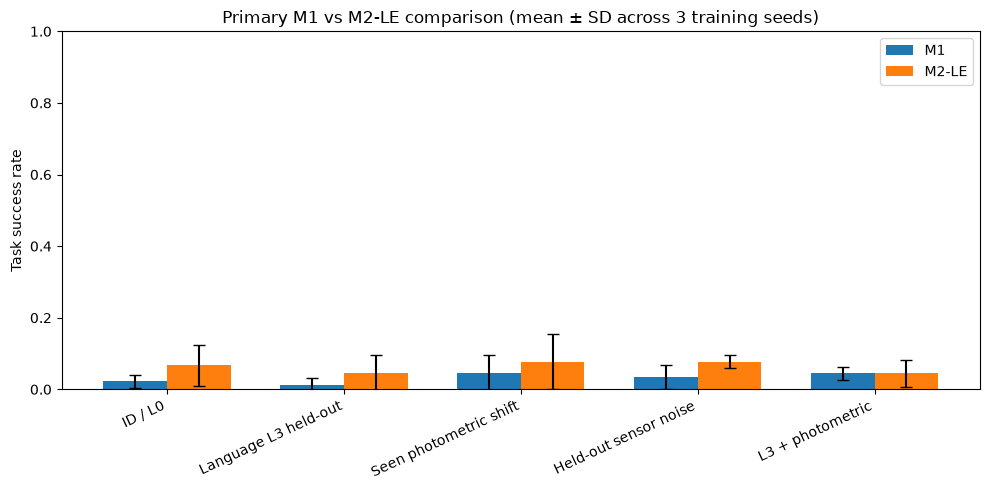

In [19]:
primary_pivot = (
    primary_multiseed_summary_df
    .pivot(
        index="condition_id",
        columns="variant",
        values="mean_success_rate",
    )
    .reindex(
        primary_conditions
    )
)

primary_sd_pivot = (
    primary_multiseed_summary_df
    .pivot(
        index="condition_id",
        columns="variant",
        values="sd_across_seeds",
    )
    .reindex(
        primary_conditions
    )
)

x = np.arange(
    len(primary_conditions)
)

width = 0.36

fig, ax = plt.subplots(
    figsize=(10, 5)
)

for offset, variant in [
    (-width / 2, "M1"),
    (width / 2, "M2-LE"),
]:
    ax.bar(
        x + offset,
        primary_pivot[
            variant
        ].to_numpy(),
        width,
        yerr=primary_sd_pivot[
            variant
        ].to_numpy(),
        capsize=4,
        label=variant,
    )

ax.set_xticks(x)

ax.set_xticklabels(
    [
        CONDITIONS[
            condition_id
        ]["label"]
        for condition_id
        in primary_conditions
    ],
    rotation=25,
    ha="right",
)

ax.set_ylim(0.0, 1.0)
ax.set_ylabel("Task success rate")
ax.set_title(
    "Primary M1 vs M2-LE comparison (mean ± SD across 3 training seeds)"
)
ax.legend()
fig.tight_layout()

primary_figure_path = (
    FIGURES_DIR
    / "primary_multiseed_success_rates.png"
)

fig.savefig(
    primary_figure_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

## 17. Language robustness analysis

,variant,condition_id,episodes,success_rate
10,M1,E0_ID,30,0.033333
11,M1,E1_L1,30,0.033333
12,M1,E1_L2,30,0.033333
13,M1,E1_L3,30,0.033333
30,M2-LE,E0_ID,30,0.000000
31,M2-LE,E1_L1,30,0.100000
32,M2-LE,E1_L2,30,0.000000
33,M2-LE,E1_L3,30,0.100000
37,M2-L,E0_ID,30,0.033333
38,M2-L,E1_L1,30,0.100000


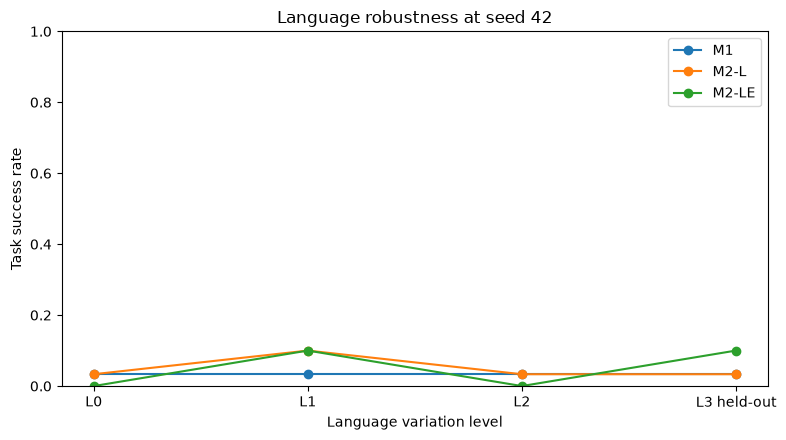

In [20]:
language_conditions = [
    "E0_ID",
    "E1_L1",
    "E1_L2",
    "E1_L3",
]

language_seed42_df = (
    condition_summary_df[
        (condition_summary_df["model_seed"] == 42)
        & condition_summary_df[
            "variant"
        ].isin(
            ["M1", "M2-L", "M2-LE"]
        )
        & condition_summary_df[
            "condition_id"
        ].isin(
            language_conditions
        )
    ]
    .copy()
)

display(
    language_seed42_df[
        [
            "variant",
            "condition_id",
            "episodes",
            "success_rate",
        ]
    ]
)

fig, ax = plt.subplots(
    figsize=(8, 4.5)
)

for variant, group in language_seed42_df.groupby(
    "variant"
):
    ordered = (
        group
        .set_index(
            "condition_id"
        )
        .reindex(
            language_conditions
        )
    )

    ax.plot(
        range(
            len(
                language_conditions
            )
        ),
        ordered[
            "success_rate"
        ],
        marker="o",
        label=variant,
    )

ax.set_xticks(
    range(
        len(
            language_conditions
        )
    )
)

ax.set_xticklabels(
    ["L0", "L1", "L2", "L3 held-out"]
)

ax.set_ylim(0.0, 1.0)
ax.set_ylabel("Task success rate")
ax.set_xlabel("Language variation level")
ax.set_title(
    "Language robustness at seed 42"
)
ax.legend()
fig.tight_layout()

language_figure_path = (
    FIGURES_DIR
    / "language_robustness_seed42.png"
)

fig.savefig(
    language_figure_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

## 18. Environmental robustness and held-out transfer

,variant,condition_id,episodes,success_rate
10,M1,E0_ID,30,0.033333
14,M1,E2_SEEN_PHOTO,30,0.100000
15,M1,E3_HELDOUT_NOISE,30,0.033333
17,M2-E,E0_ID,30,0.000000
18,M2-E,E2_SEEN_PHOTO,30,0.033333
19,M2-E,E3_HELDOUT_NOISE,30,0.066667
30,M2-LE,E0_ID,30,0.000000
34,M2-LE,E2_SEEN_PHOTO,30,0.033333
35,M2-LE,E3_HELDOUT_NOISE,30,0.100000


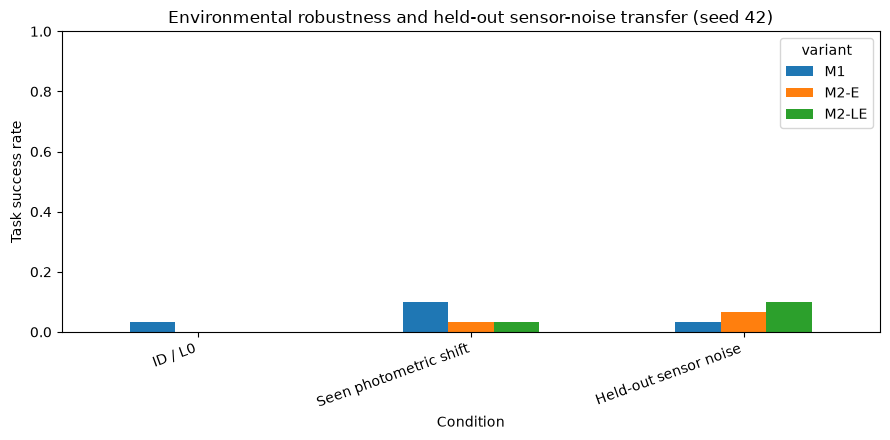

In [21]:
environment_conditions = [
    "E0_ID",
    "E2_SEEN_PHOTO",
    "E3_HELDOUT_NOISE",
]

environment_seed42_df = (
    condition_summary_df[
        (condition_summary_df["model_seed"] == 42)
        & condition_summary_df[
            "variant"
        ].isin(
            ["M1", "M2-E", "M2-LE"]
        )
        & condition_summary_df[
            "condition_id"
        ].isin(
            environment_conditions
        )
    ]
    .copy()
)

display(
    environment_seed42_df[
        [
            "variant",
            "condition_id",
            "episodes",
            "success_rate",
        ]
    ]
)

environment_pivot = (
    environment_seed42_df
    .pivot(
        index="condition_id",
        columns="variant",
        values="success_rate",
    )
    .reindex(
        environment_conditions
    )
)

fig, ax = plt.subplots(
    figsize=(9, 4.5)
)

environment_pivot.plot(
    kind="bar",
    ax=ax,
)

ax.set_ylim(0.0, 1.0)
ax.set_ylabel("Task success rate")
ax.set_xlabel("Condition")
ax.set_title(
    "Environmental robustness and held-out sensor-noise transfer (seed 42)"
)
ax.set_xticklabels(
    [
        CONDITIONS[
            condition_id
        ]["label"]
        for condition_id
        in environment_conditions
    ],
    rotation=20,
    ha="right",
)

fig.tight_layout()

environment_figure_path = (
    FIGURES_DIR
    / "environment_robustness_seed42.png"
)

fig.savefig(
    environment_figure_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

## 19. Generalization-gap analysis

In [22]:
id_lookup = (
    condition_summary_df[
        condition_summary_df[
            "condition_id"
        ]
        == "E0_ID"
    ]
    .set_index(
        [
            "run_id",
            "variant",
            "model_seed",
        ]
    )[
        "success_rate"
    ]
    .to_dict()
)

gap_rows = []

for row in condition_summary_df.itertuples():
    if row.condition_id == "E0_ID":
        continue

    id_key = (
        row.run_id,
        row.variant,
        int(row.model_seed),
    )

    if id_key not in id_lookup:
        continue

    id_sr = float(
        id_lookup[id_key]
    )

    condition_sr = float(
        row.success_rate
    )

    gap_rows.append({
        "run_id": row.run_id,
        "variant": row.variant,
        "model_seed": int(
            row.model_seed
        ),
        "condition_id": row.condition_id,
        "id_success_rate": id_sr,
        "condition_success_rate": condition_sr,
        "generalization_gap": (
            id_sr - condition_sr
        ),
    })

generalization_gap_df = (
    pd.DataFrame(
        gap_rows
    )
)

display(
    generalization_gap_df.sort_values(
        [
            "variant",
            "model_seed",
            "condition_id",
        ]
    )
)

generalization_gap_df.to_csv(
    METRICS_DIR
    / "generalization_gaps.csv",
    index=False,
)

primary_gap_summary_df = (
    generalization_gap_df[
        generalization_gap_df[
            "variant"
        ].isin(
            ["M1", "M2-LE"]
        )
        & generalization_gap_df[
            "model_seed"
        ].isin(
            PRIMARY_SEEDS
        )
        & generalization_gap_df[
            "condition_id"
        ].isin(
            [
                condition
                for condition in primary_conditions
                if condition != "E0_ID"
            ]
        )
    ]
    .groupby(
        [
            "variant",
            "condition_id",
        ],
        as_index=False,
    )
    .agg(
        mean_generalization_gap=(
            "generalization_gap",
            "mean",
        ),
        sd_generalization_gap=(
            "generalization_gap",
            "std",
        ),
    )
)

display(primary_gap_summary_df)

print("GENERALIZATION GAP ANALYSIS: PASS")

,run_id,variant,model_seed,condition_id,id_success_rate,condition_success_rate,generalization_gap
8,M1_seed42,M1,42,E1_L1,0.033333,0.033333,0.000000
9,M1_seed42,M1,42,E1_L2,0.033333,0.033333,0.000000
10,M1_seed42,M1,42,E1_L3,0.033333,0.033333,0.000000
11,M1_seed42,M1,42,E2_SEEN_PHOTO,0.033333,0.100000,-0.066667
12,M1_seed42,M1,42,E3_HELDOUT_NOISE,0.033333,0.033333,0.000000
13,M1_seed42,M1,42,E4_COMBINED,0.033333,0.066667,-0.033333
0,M1_seed123,M1,123,E1_L3,0.033333,0.000000,0.033333
1,M1_seed123,M1,123,E2_SEEN_PHOTO,0.033333,0.000000,0.033333
2,M1_seed123,M1,123,E3_HELDOUT_NOISE,0.033333,0.000000,0.033333
3,M1_seed123,M1,123,E4_COMBINED,0.033333,0.033333,0.000000


,variant,condition_id,mean_generalization_gap,sd_generalization_gap
0,M1,E1_L3,0.011111,0.019245
1,M1,E2_SEEN_PHOTO,-0.022222,0.050918
2,M1,E3_HELDOUT_NOISE,-0.011111,0.050918
3,M1,E4_COMBINED,-0.022222,0.019245
4,M2-LE,E1_L3,0.022222,0.107152
5,M2-LE,E2_SEEN_PHOTO,-0.011111,0.069389
6,M2-LE,E3_HELDOUT_NOISE,-0.011111,0.076980
7,M2-LE,E4_COMBINED,0.022222,0.083887


GENERALIZATION GAP ANALYSIS: PASS


## 20. Paired M1 vs M2-LE success comparison

The same task/replica evaluation seeds are used across M1 and M2-LE, allowing a paired binary comparison.

For each training seed and primary condition we report:

- M1 success rate,
- M2-LE success rate,
- percentage-point difference,
- discordant pairs,
- exact two-sided McNemar/binomial p-value.

With only three training seeds, these episode-level tests are treated as **supporting evidence**, not a substitute for reporting seed-to-seed variation.

In [23]:
def exact_mcnemar_pvalue(
    b: int,
    c: int,
):
    n = int(
        b + c
    )

    if n == 0:
        return 1.0

    k = min(
        int(b),
        int(c),
    )

    lower_tail = sum(
        math.comb(
            n,
            i,
        )
        for i in range(
            k + 1
        )
    ) / (
        2 ** n
    )

    return min(
        1.0,
        2.0 * lower_tail,
    )


paired_rows = []

for model_seed in PRIMARY_SEEDS:
    for condition_id in primary_conditions:
        left = primary_episode_df[
            (primary_episode_df["variant"] == "M1")
            & (primary_episode_df["model_seed"] == model_seed)
            & (primary_episode_df["condition_id"] == condition_id)
        ][
            [
                "suite_task_id",
                "replica",
                "success",
            ]
        ].rename(
            columns={
                "success": "m1_success"
            }
        )

        right = primary_episode_df[
            (primary_episode_df["variant"] == "M2-LE")
            & (primary_episode_df["model_seed"] == model_seed)
            & (primary_episode_df["condition_id"] == condition_id)
        ][
            [
                "suite_task_id",
                "replica",
                "success",
            ]
        ].rename(
            columns={
                "success": "m2le_success"
            }
        )

        paired = left.merge(
            right,
            on=[
                "suite_task_id",
                "replica",
            ],
            how="inner",
            validate="one_to_one",
        )

        assert len(
            paired
        ) == (
            10
            * EPISODES_PER_TASK
        )

        m1_success = (
            paired[
                "m1_success"
            ]
            .astype(bool)
        )

        m2le_success = (
            paired[
                "m2le_success"
            ]
            .astype(bool)
        )

        b = int(
            (
                m1_success
                & ~m2le_success
            ).sum()
        )

        c = int(
            (
                ~m1_success
                & m2le_success
            ).sum()
        )

        paired_rows.append({
            "model_seed": int(model_seed),
            "condition_id": condition_id,
            "paired_episodes": len(paired),
            "m1_success_rate": float(
                m1_success.mean()
            ),
            "m2le_success_rate": float(
                m2le_success.mean()
            ),
            "m2le_minus_m1_pp": float(
                (
                    m2le_success.mean()
                    - m1_success.mean()
                )
                * 100.0
            ),
            "m1_only_successes_b": b,
            "m2le_only_successes_c": c,
            "exact_p_value": float(
                exact_mcnemar_pvalue(
                    b,
                    c,
                )
            ),
        })

paired_comparison_df = pd.DataFrame(
    paired_rows
)

display(paired_comparison_df)

paired_comparison_df.to_csv(
    METRICS_DIR
    / "paired_m1_vs_m2le.csv",
    index=False,
)

print("PAIRED SUCCESS COMPARISON: PASS")

,model_seed,condition_id,paired_episodes,m1_success_rate,m2le_success_rate,m2le_minus_m1_pp,m1_only_successes_b,m2le_only_successes_c,exact_p_value
0,42,E0_ID,30,0.033333,0.000000,-3.333333,1,0,1.0000
1,42,E1_L3,30,0.033333,0.100000,6.666667,1,3,0.6250
2,42,E2_SEEN_PHOTO,30,0.100000,0.033333,-6.666667,3,1,0.6250
3,42,E3_HELDOUT_NOISE,30,0.033333,0.100000,6.666667,1,3,0.6250
4,42,E4_COMBINED,30,0.066667,0.066667,0.000000,2,2,1.0000
5,123,E0_ID,30,0.033333,0.100000,6.666667,1,3,0.6250
6,123,E1_L3,30,0.000000,0.033333,3.333333,0,1,1.0000
7,123,E2_SEEN_PHOTO,30,0.000000,0.166667,16.666667,0,5,0.0625
8,123,E3_HELDOUT_NOISE,30,0.000000,0.066667,6.666667,0,2,0.5000
9,123,E4_COMBINED,30,0.033333,0.066667,3.333333,1,2,1.0000


PAIRED SUCCESS COMPARISON: PASS


## 21. Per-task success heatmaps

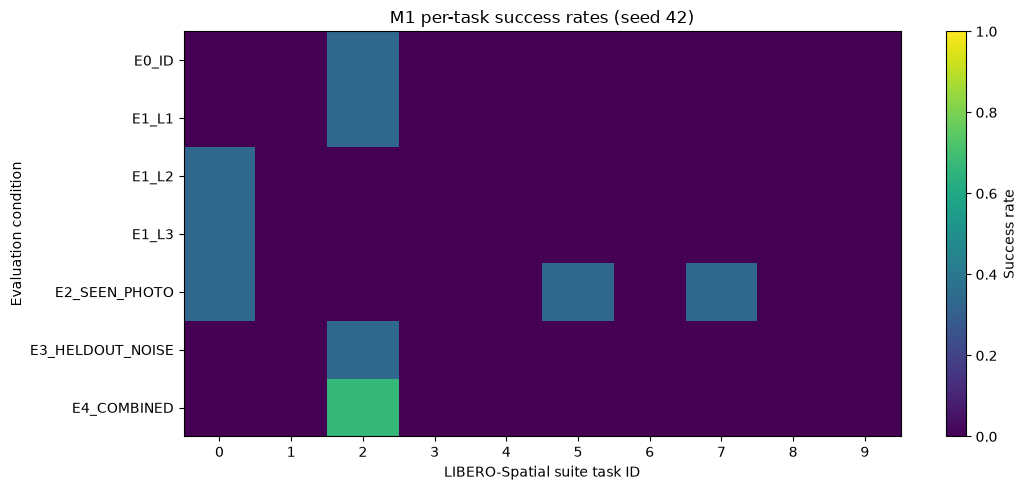

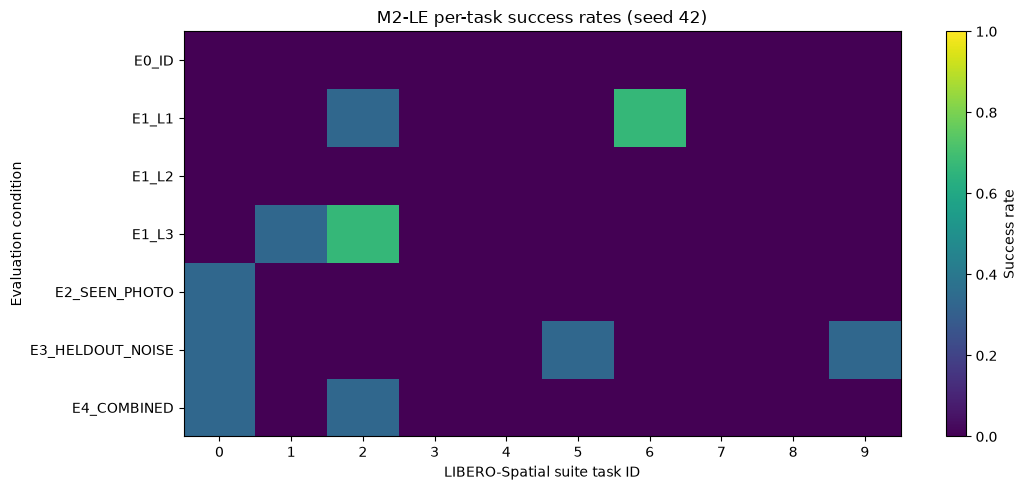

PER-TASK HEATMAPS: PASS


In [24]:
seed42_primary_task_df = (
    episode_results_df[
        (episode_results_df["model_seed"] == 42)
        & episode_results_df[
            "variant"
        ].isin(
            ["M1", "M2-LE"]
        )
    ]
    .groupby(
        [
            "variant",
            "condition_id",
            "suite_task_id",
        ],
        as_index=False,
    )
    .agg(
        success_rate=("success", "mean")
    )
)

for variant in [
    "M1",
    "M2-LE",
]:
    variant_df = (
        seed42_primary_task_df[
            seed42_primary_task_df[
                "variant"
            ]
            == variant
        ]
        .pivot(
            index="condition_id",
            columns="suite_task_id",
            values="success_rate",
        )
        .reindex(
            [
                condition_id
                for condition_id
                in CONDITIONS
                if condition_id
                in seed42_primary_task_df[
                    "condition_id"
                ].unique()
            ]
        )
    )

    fig, ax = plt.subplots(
        figsize=(11, 5)
    )

    image = ax.imshow(
        variant_df.to_numpy(),
        aspect="auto",
        vmin=0.0,
        vmax=1.0,
    )

    ax.set_xticks(
        range(
            len(
                variant_df.columns
            )
        )
    )

    ax.set_xticklabels(
        variant_df.columns
    )

    ax.set_yticks(
        range(
            len(
                variant_df.index
            )
        )
    )

    ax.set_yticklabels(
        variant_df.index
    )

    ax.set_xlabel(
        "LIBERO-Spatial suite task ID"
    )

    ax.set_ylabel(
        "Evaluation condition"
    )

    ax.set_title(
        f"{variant} per-task success rates (seed 42)"
    )

    fig.colorbar(
        image,
        ax=ax,
        label="Success rate",
    )

    fig.tight_layout()

    path = (
        FIGURES_DIR
        / f"{variant.lower().replace('-', '')}_task_heatmap_seed42.png"
    )

    fig.savefig(
        path,
        dpi=180,
        bbox_inches="tight",
    )

    plt.show()

print("PER-TASK HEATMAPS: PASS")

## 22. Offline validation loss vs closed-loop ID success

This diagnostic checks whether the offline validation loss used for model selection is strongly aligned with actual closed-loop ID success.

A weak relationship would reinforce why Notebook 04 uses task success—not imitation loss—as the primary research outcome.

,run_id,variant,model_seed,validation_loss,success_rate
0,M1_seed42,M1,42,0.647234,0.033333
1,M1_seed123,M1,123,0.663268,0.033333
2,M1_seed2026,M1,2026,0.662571,0.000000
3,M2E_seed42,M2-E,42,0.642406,0.000000
4,M2L_seed42,M2-L,42,0.657187,0.033333
5,M2LE_seed42,M2-LE,42,0.653671,0.000000
6,M2LE_seed123,M2-LE,123,0.700583,0.100000
7,M2LE_seed2026,M2-LE,2026,0.644916,0.100000


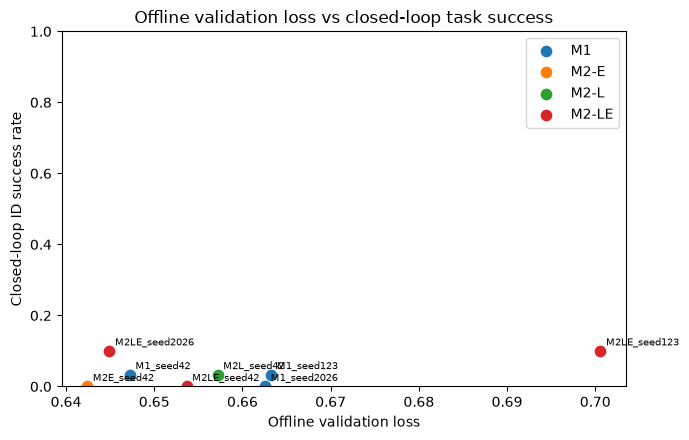

In [25]:
id_success_by_run = (
    condition_summary_df[
        condition_summary_df[
            "condition_id"
        ]
        == "E0_ID"
    ][
        [
            "run_id",
            "variant",
            "model_seed",
            "success_rate",
        ]
    ]
)

offline_vs_closed_loop_df = (
    model_registry_df[
        [
            "run_id",
            "variant",
            "seed",
            "validation_loss",
        ]
    ]
    .rename(
        columns={
            "seed": "model_seed"
        }
    )
    .merge(
        id_success_by_run,
        on=[
            "run_id",
            "variant",
            "model_seed",
        ],
        how="inner",
        validate="one_to_one",
    )
)

display(
    offline_vs_closed_loop_df
)

fig, ax = plt.subplots(
    figsize=(7, 4.5)
)

for variant, group in offline_vs_closed_loop_df.groupby(
    "variant"
):
    ax.scatter(
        group[
            "validation_loss"
        ],
        group[
            "success_rate"
        ],
        label=variant,
        s=55,
    )

    for row in group.itertuples():
        ax.annotate(
            row.run_id,
            (
                row.validation_loss,
                row.success_rate,
            ),
            fontsize=7,
            xytext=(4, 4),
            textcoords="offset points",
        )

ax.set_xlabel(
    "Offline validation loss"
)

ax.set_ylabel(
    "Closed-loop ID success rate"
)

ax.set_ylim(
    0.0,
    1.0,
)

ax.set_title(
    "Offline validation loss vs closed-loop task success"
)

ax.legend()
fig.tight_layout()

offline_relation_figure_path = (
    FIGURES_DIR
    / "offline_loss_vs_closed_loop_success.png"
)

fig.savefig(
    offline_relation_figure_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

## 23. Failure-proxy analysis and qualitative review template

Automatic logs can reliably identify only coarse terminal outcomes such as success and timeout.

They cannot reliably determine whether a failure was caused by:

- F01 localization,
- F02 wrong target,
- F03 failed grasp,
- F04 slip,
- F05 placement,
- F06 language understanding,
- F07 trajectory/control,
- F08 timeout,
- F09 collision/environment,
- F10 other.

Therefore this notebook **does not fabricate detailed failure labels**.

Instead it:

1. reports automatic terminal proxies,
2. saves representative task-0 image pairs,
3. creates a manual-review table for a small, curated subset of failures.

In [26]:
failure_proxy_summary_df = (
    episode_results_df
    .groupby(
        [
            "variant",
            "model_seed",
            "condition_id",
            "failure_proxy",
        ],
        as_index=False,
    )
    .size()
    .rename(
        columns={
            "size": "episodes"
        }
    )
)

display(failure_proxy_summary_df)

failure_proxy_summary_df.to_csv(
    METRICS_DIR
    / "failure_proxy_summary.csv",
    index=False,
)

FAILURE_CODEBOOK = {
    "F01": "Localization/perception failure",
    "F02": "Wrong target/object selection",
    "F03": "Failed grasp",
    "F04": "Object slip after grasp",
    "F05": "Placement failure",
    "F06": "Language/instruction misunderstanding",
    "F07": "Trajectory/control failure",
    "F08": "Timeout/incomplete execution",
    "F09": "Collision/environment interaction",
    "F10": "Other",
}

with open(
    EXPERIMENT_CONFIG_DIR
    / "failure_taxonomy_v1.json",
    "w",
) as f:
    json.dump(
        FAILURE_CODEBOOK,
        f,
        indent=2,
    )

failed_primary_seed42 = (
    episode_results_df[
        (~episode_results_df["success"])
        & (episode_results_df["model_seed"] == 42)
        & episode_results_df[
            "variant"
        ].isin(
            ["M1", "M2-LE"]
        )
    ]
    .sort_values(
        [
            "condition_id",
            "variant",
            "suite_task_id",
            "replica",
        ]
    )
)

review_rows = []

for (
    variant,
    condition_id,
), group in failed_primary_seed42.groupby(
    [
        "variant",
        "condition_id",
    ]
):
    sample = group.head(2)

    for row in sample.itertuples():
        review_rows.append({
            "run_id": row.run_id,
            "variant": variant,
            "condition_id": condition_id,
            "suite_task_id": int(
                row.suite_task_id
            ),
            "replica": int(
                row.replica
            ),
            "automatic_proxy": row.failure_proxy,
            "manual_failure_code": "",
            "manual_review_status": "PENDING",
            "review_note": "",
        })

failure_review_df = pd.DataFrame(
    review_rows
)

failure_review_path = (
    METRICS_DIR
    / "failure_review_template.csv"
)

failure_review_df.to_csv(
    failure_review_path,
    index=False,
)

display(
    failure_review_df.head(20)
)

print(
    "Manual failure review template:",
    failure_review_path,
)

,variant,model_seed,condition_id,failure_proxy,episodes
0,M1,42,E0_ID,SUCCESS,1
1,M1,42,E0_ID,TIMEOUT,29
2,M1,42,E1_L1,SUCCESS,1
3,M1,42,E1_L1,TIMEOUT,29
4,M1,42,E1_L2,SUCCESS,1
...,...,...,...,...,...
67,M2-LE,2026,E2_SEEN_PHOTO,SUCCESS,1
68,M2-LE,2026,E2_SEEN_PHOTO,TIMEOUT,29
69,M2-LE,2026,E3_HELDOUT_NOISE,SUCCESS,2
70,M2-LE,2026,E3_HELDOUT_NOISE,TIMEOUT,28


,run_id,variant,condition_id,suite_task_id,replica,automatic_proxy,manual_failure_code,manual_review_status,review_note
0,M1_seed42,M1,E0_ID,0,0,TIMEOUT,,PENDING,
1,M1_seed42,M1,E0_ID,0,1,TIMEOUT,,PENDING,
2,M1_seed42,M1,E1_L1,0,0,TIMEOUT,,PENDING,
3,M1_seed42,M1,E1_L1,0,1,TIMEOUT,,PENDING,
4,M1_seed42,M1,E1_L2,0,0,TIMEOUT,,PENDING,
5,M1_seed42,M1,E1_L2,0,1,TIMEOUT,,PENDING,
6,M1_seed42,M1,E1_L3,0,0,TIMEOUT,,PENDING,
7,M1_seed42,M1,E1_L3,0,1,TIMEOUT,,PENDING,
8,M1_seed42,M1,E2_SEEN_PHOTO,0,0,TIMEOUT,,PENDING,
9,M1_seed42,M1,E2_SEEN_PHOTO,0,2,TIMEOUT,,PENDING,


Manual failure review template: /home/leeming/projects/deep-learning-vla-robustness/results/metrics/evaluation_critical_analysis/failure_review_template.csv


## 24. Research-question evidence table

In [27]:
def multiseed_mean(
    variant,
    condition_id,
):
    subset = (
        primary_multiseed_summary_df[
            (
                primary_multiseed_summary_df[
                    "variant"
                ]
                == variant
            )
            & (
                primary_multiseed_summary_df[
                    "condition_id"
                ]
                == condition_id
            )
        ]
    )

    if subset.empty:
        return np.nan

    return float(
        subset.iloc[0][
            "mean_success_rate"
        ]
    )


m1_id = multiseed_mean(
    "M1",
    "E0_ID",
)

m2le_id = multiseed_mean(
    "M2-LE",
    "E0_ID",
)

m1_l3 = multiseed_mean(
    "M1",
    "E1_L3",
)

m2le_l3 = multiseed_mean(
    "M2-LE",
    "E1_L3",
)

m1_photo = multiseed_mean(
    "M1",
    "E2_SEEN_PHOTO",
)

m2le_photo = multiseed_mean(
    "M2-LE",
    "E2_SEEN_PHOTO",
)

m1_noise = multiseed_mean(
    "M1",
    "E3_HELDOUT_NOISE",
)

m2le_noise = multiseed_mean(
    "M2-LE",
    "E3_HELDOUT_NOISE",
)

m1_combined = multiseed_mean(
    "M1",
    "E4_COMBINED",
)

m2le_combined = multiseed_mean(
    "M2-LE",
    "E4_COMBINED",
)

rq_rows = [
    {
        "research_question": "RQ1",
        "evidence": (
            "Seen photometric success: "
            f"M1={m1_photo:.3f}, "
            f"M2-LE={m2le_photo:.3f}"
        ),
        "m2le_minus_m1_pp": (
            m2le_photo - m1_photo
        ) * 100.0,
        "interpretation_scope": (
            "Directional evidence under the tested seen photometric shift"
        ),
    },
    {
        "research_question": "RQ2",
        "evidence": (
            "Held-out L3 success: "
            f"M1={m1_l3:.3f}, "
            f"M2-LE={m2le_l3:.3f}; "
            "seed-42 L0-L3 curves reported separately"
        ),
        "m2le_minus_m1_pp": (
            m2le_l3 - m1_l3
        ) * 100.0,
        "interpretation_scope": (
            "Linguistic generalization under the curated L3 paraphrase set"
        ),
    },
    {
        "research_question": "RQ3",
        "evidence": (
            "M1 tested visual shifts: "
            f"photometric={m1_photo:.3f}, "
            f"noise={m1_noise:.3f}"
        ),
        "m2le_minus_m1_pp": np.nan,
        "interpretation_scope": (
            "Strongest degradation among the two implemented visual perturbations only"
        ),
    },
    {
        "research_question": "RQ4",
        "evidence": (
            "Held-out sensor-noise success: "
            f"M1={m1_noise:.3f}, "
            f"M2-LE={m2le_noise:.3f}"
        ),
        "m2le_minus_m1_pp": (
            m2le_noise - m1_noise
        ) * 100.0,
        "interpretation_scope": (
            "Transfer to a held-out visual perturbation category"
        ),
    },
    {
        "research_question": "RQ5",
        "evidence": (
            "ID success: "
            f"M1={m1_id:.3f}, "
            f"M2-LE={m2le_id:.3f}"
        ),
        "m2le_minus_m1_pp": (
            m2le_id - m1_id
        ) * 100.0,
        "interpretation_scope": (
            "ID performance trade-off; OOD benefits must be interpreted jointly"
        ),
    },
]

rq_evidence_df = pd.DataFrame(
    rq_rows
)

display(rq_evidence_df)

rq_evidence_df.to_csv(
    METRICS_DIR
    / "research_question_evidence.csv",
    index=False,
)

print("RESEARCH-QUESTION EVIDENCE TABLE: PASS")

,research_question,evidence,m2le_minus_m1_pp,interpretation_scope
0,RQ1,"Seen photometric success: M1=0.044, M2-LE=0.078",3.333333,Directional evidence under the tested seen pho...
1,RQ2,"Held-out L3 success: M1=0.011, M2-LE=0.044; se...",3.333333,Linguistic generalization under the curated L3...
2,RQ3,"M1 tested visual shifts: photometric=0.044, no...",NaN,Strongest degradation among the two implemente...
3,RQ4,"Held-out sensor-noise success: M1=0.033, M2-LE...",4.444444,Transfer to a held-out visual perturbation cat...
4,RQ5,"ID success: M1=0.022, M2-LE=0.067",4.444444,ID performance trade-off; OOD benefits must be...


RESEARCH-QUESTION EVIDENCE TABLE: PASS


## 25. Critical-analysis guardrails

When writing the report, interpret the results using the following rules:

1. **Do not equate lower offline validation loss with higher robotic success.**
2. **Report per-seed bootstrap CIs and across-seed SD separately.**
3. **Do not claim that Gaussian sensor noise represents all environmental shifts.**
4. **Do not claim camera/layout robustness unless those perturbations are actually implemented.**
5. If M2-LE does not outperform M1, treat the null/negative result as meaningful:
   - the pretrained VLM may already provide language invariance,
   - the augmentation strength may be insufficient,
   - combined augmentation may increase optimization variance,
   - short LIBERO instructions may limit the useful paraphrase space.
6. Use M2-L and M2-E as ablations to identify whether language or visual augmentation contributes independently.
7. Treat the detailed F01–F10 failure taxonomy as **manual qualitative analysis**, not an automatically inferred label.

## 26. Final notebook status and reproducibility summary

In [28]:
required_primary_cells = (
    len(PRIMARY_SEEDS)
    * len(primary_conditions)
    * 2
)

observed_primary_cells = (
    primary_seed_sr_df[
        [
            "variant",
            "model_seed",
            "condition_id",
        ]
    ]
    .drop_duplicates()
    .shape[0]
)

final_checks = {
    "Notebook 03 prerequisite":
        notebook03_summary["status"] == "PASS",

    "Eight final checkpoints present":
        (
            len(model_registry_df) == 8
            and model_registry_df[
                "checkpoint_exists"
            ].all()
        ),

    "Training trace finite":
        TRAINING_TRACE_PASS,

    "Architecture visualization":
        architecture_figure_path.exists(),

    "Task/language mapping":
        (
            len(task_mapping_df) == 10
            and len(language_df) == 40
        ),

    "Evaluation conditions frozen":
        condition_manifest_path.exists(),

    "Evaluation compute budget frozen":
        (
            evaluation_plan_path.exists()
            and PLANNED_EPISODES == 1230
        ),

    "G1 timing calibration":
        G1_TIMING_PASS,

    "All planned closed-loop episodes":
        (
            FULL_EVALUATION_PASS
            and len(
                episode_results_df
            )
            == PLANNED_EPISODES
        ),

    "Primary three-seed comparison":
        (
            observed_primary_cells
            == required_primary_cells
        ),

    "Per-seed bootstrap uncertainty":
        (
            not bootstrap_ci_df.empty
            and np.isfinite(
                bootstrap_ci_df[
                    [
                        "success_rate",
                        "bootstrap_ci_low",
                        "bootstrap_ci_high",
                    ]
                ].to_numpy()
            ).all()
        ),

    "Across-seed variation":
        (
            not primary_multiseed_summary_df.empty
            and (
                primary_multiseed_summary_df[
                    "seed_count"
                ]
                == 3
            ).all()
        ),

    "Generalization gaps":
        not generalization_gap_df.empty,

    "Paired M1 vs M2-LE comparison":
        (
            len(
                paired_comparison_df
            )
            == (
                len(
                    PRIMARY_SEEDS
                )
                * len(
                    primary_conditions
                )
            )
        ),

    "Failure analysis outputs":
        (
            (
                METRICS_DIR
                / "failure_proxy_summary.csv"
            ).exists()
            and failure_review_path.exists()
        ),

    "Research-question evidence":
        (
            len(
                rq_evidence_df
            )
            == 5
        ),

    "Primary performance figure":
        primary_figure_path.exists(),

    "Language robustness figure":
        language_figure_path.exists(),

    "Environmental robustness figure":
        environment_figure_path.exists(),
}

# Normalize NumPy/Pandas scalar booleans before JSON serialization.
final_checks = {
    check: bool(value)
    for check, value in final_checks.items()
}

status_df = pd.DataFrame(
    [
        {
            "check": check,
            "status": (
                "PASS"
                if passed
                else "FAIL"
            ),
        }
        for check, passed in final_checks.items()
    ]
)

display(status_df)

NOTEBOOK_04_PASS = bool(
    all(
        final_checks.values()
    )
)

notebook04_summary = {
    "notebook": (
        "04_evaluation_and_critical_analysis"
    ),
    "status": (
        "PASS"
        if NOTEBOOK_04_PASS
        else "FAIL"
    ),
    "project_git_sha": PROJECT_GIT_SHA,
    "source_notebook03": str(
        NOTEBOOK03_SUMMARY_PATH.relative_to(
            REPO_ROOT
        )
    ),
    "dataset_repo_id": evaluation_handoff[
        "dataset_repo_id"
    ],
    "dataset_revision": evaluation_handoff[
        "dataset_revision"
    ],
    "split_sha256": evaluation_handoff[
        "split_sha256"
    ],
    "planned_episodes": int(
        PLANNED_EPISODES
    ),
    "completed_episodes": int(
        len(
            episode_results_df
        )
    ),
    "episodes_per_task": int(
        EPISODES_PER_TASK
    ),
    "bootstrap_samples": int(
        BOOTSTRAP_SAMPLES
    ),
    "primary_metric": (
        "closed-loop task success rate"
    ),
    "primary_comparison": (
        "M1 vs M2-LE across seeds 42, 123, 2026"
    ),
    "implemented_shifts": [
        "L1 lexical language variation",
        "L2 syntactic language variation",
        "L3 held-out compositional paraphrase",
        "seen photometric boundary shift",
        "held-out Gaussian sensor noise",
        "combined L3 + seen photometric shift",
    ],
    "scope_exclusions": [
        "camera viewpoint perturbation",
        "explicit object-layout perturbation",
        "explicit robot-initial-state perturbation",
        "full LIBERO-Plus benchmark adoption",
    ],
    "g1_timing": g1_summary,
    "checks": final_checks,
}

summary_path = (
    METRICS_DIR
    / "notebook04_summary.json"
)

with open(
    summary_path,
    "w",
) as f:
    json.dump(
        notebook04_summary,
        f,
        indent=2,
    )

print("=" * 72)
print("NOTEBOOK 04 — FINAL STATUS")
print("=" * 72)

for check, passed in final_checks.items():
    print(
        f"{check:<54} "
        f"{'PASS' if passed else 'FAIL'}"
    )

print("-" * 72)

print(
    f"{'NOTEBOOK 04 STATUS':<54} "
    f"{'PASS' if NOTEBOOK_04_PASS else 'FAIL'}"
)

print("-" * 72)

assert NOTEBOOK_04_PASS

print()
print("Closed-loop evaluation and critical-analysis artifacts are complete.")
print("Summary saved:", summary_path)

,check,status
0,Notebook 03 prerequisite,PASS
1,Eight final checkpoints present,PASS
2,Training trace finite,PASS
3,Architecture visualization,PASS
4,Task/language mapping,PASS
5,Evaluation conditions frozen,PASS
6,Evaluation compute budget frozen,PASS
7,G1 timing calibration,PASS
8,All planned closed-loop episodes,PASS
9,Primary three-seed comparison,PASS


NOTEBOOK 04 — FINAL STATUS
Notebook 03 prerequisite                               PASS
Eight final checkpoints present                        PASS
Training trace finite                                  PASS
Architecture visualization                             PASS
Task/language mapping                                  PASS
Evaluation conditions frozen                           PASS
Evaluation compute budget frozen                       PASS
G1 timing calibration                                  PASS
All planned closed-loop episodes                       PASS
Primary three-seed comparison                          PASS
Per-seed bootstrap uncertainty                         PASS
Across-seed variation                                  PASS
Generalization gaps                                    PASS
Paired M1 vs M2-LE comparison                          PASS
Failure analysis outputs                               PASS
Research-question evidence                             PASS
Primary perfo

## Final interpretation boundary

A successful Notebook 04 means the project now contains:

- a reproducible LIBERO-Spatial data audit,
- a validated closed-loop SmolVLA baseline,
- controlled robustness training methods,
- hyperparameter tuning and final model training,
- single-seed ablations,
- multi-seed primary comparison,
- closed-loop ID/OOD evaluation,
- separate evaluation and training uncertainty,
- generalization-gap analysis,
- paired success analysis,
- architecture and performance visualization,
- transparent failure-analysis limits,
- evidence mapped directly to the research questions.

The final report should use these artifacts to make only the claims supported by the measured conditions.